# Modular Exponentiation with Ripple-Carry Adders

This notebook constructs reversible quantum arithmetic circuits in Qiskit and compares two ripple-carry adder families: **CDKM** (MAJ/UMA) and **VBE** (SUM/CARRY). The construction progresses from binary addition to modular addition, controlled modular multiplication, and modular exponentiation, an arithmetic building block used in Shor's algorithm.

### Contents

1. Build SUM/CARRY and MAJ/UMA adders from elementary gates.
2. Verify Qiskit's VBE and CDKM adders against classical arithmetic.
3. Construct modular adders and controlled modular multipliers.
4. Construct modular exponentiation using each adder family.
5. Compare logical gate counts, circuit depths, and qubit requirements.
6. Evaluate the derived expressions at a 2,048-bit modulus width.

### Measurement methodology and scope

- Resource counts are obtained by transpiling to the **`u` and `cx`** basis at **`optimization_level=0`**. This fixes the optimization setting for comparison; exact decompositions and counts can still depend on the Qiskit version.
- Resource figures count the arithmetic circuit only. Input-state preparation, measurements, device routing, and quantum error correction are excluded.
- The notebook checks selected inputs with simulation and assertions. These examples are not exhaustive correctness proofs.
- The scaling formulas describe the displayed, unoptimized constructions. They are not optimized implementations of RSA factoring or physical-hardware resource estimates.
- Reversible modular multiplication assumes the chosen base is coprime to the modulus when a modular inverse is required.

## Common circuit utilities

The next cell defines register preparation, measurement decoding, circuit composition, and resource counting. Run cells in order because later sections reuse these functions.

In [1]:
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit.circuit.library import CDKMRippleCarryAdder, VBERippleCarryAdder
from qiskit_aer import AerSimulator

BASIS_GATES = ["u", "cx"]

def resource_analysis(circuit: QuantumCircuit, label: str = "Resource analysis"):
    """Print and return gate count, depth, and qubit count."""
    decomposed = transpile(
        circuit,
        basis_gates=BASIS_GATES,
        optimization_level=0
    )

    counts = decomposed.count_ops()
    u = int(counts.get("u", 0))
    cx = int(counts.get("cx", 0))

    resources = {
        "u": u,
        "cx": cx,
        "total": u + cx,
        "depth": decomposed.depth(),
        "qubits": circuit.num_qubits,
    }

    print(
        f"{label}: "
        f"1Q gates={u}, "
        f"2Q gates={cx}, "
        f"total={resources['total']}, "
        f"depth={resources['depth']}, "
        f"qubits={resources['qubits']}"
    )

    return resources

def modeexp_resource_analysis(builder, n: int, base: int, modulus: int, qubits: int):
    """
    This avoids transpiling the entire nested MODEXP circuit at once. Each
    CMODMULT component is still analyzed by resource_analysis().
    """
    constants = [pow(base, 1 << i, modulus) for i in range(n)]
    inverses = [pow(A_i, -1, modulus) for A_i in constants]

    cache = {
        value: resource_analysis(builder(n, value, modulus))
        for value in set(constants + inverses)
    }

    u = sum(
        cache[A_i]["u"] + cache[A_inv]["u"]
        for A_i, A_inv in zip(constants, inverses)
    )

    cx = sum(
        cache[A_i]["cx"] + cache[A_inv]["cx"]
        for A_i, A_inv in zip(constants, inverses)
    ) + 3 * n**2

    depth = sum(
        cache[A_i]["depth"] + 3 + cache[A_inv]["depth"]
        for A_i, A_inv in zip(constants, inverses)
    )

    resources = {
        "u": u,
        "cx": cx,
        "total": u + cx,
        "depth": depth,
        "qubits": qubits,
    }

    print(
        "Resource analysis: "
        f"1Q gates={resources['u']}, "
        f"2Q gates={resources['cx']}, "
        f"total={resources['total']}, "
        f"depth={resources['depth']}, "
        f"qubits={resources['qubits']}"
    )

    return resources

def state_prep(circuit: QuantumCircuit, values: dict):
    """Initialize registers. Unspecified registers stay in |0>."""
    reg_map = {reg.name: reg for reg in circuit.qregs}
    prep = QuantumCircuit(*circuit.qregs, name="State_Preparation")

    for name, value in values.items():
        prep.initialize(value, reg_map[name])

    return prep.compose(circuit), reg_map

def run_circuit(circuit: QuantumCircuit, inputs: dict):
    """Run the circuit and return each measured register as an integer."""
    qc, reg_map = state_prep(circuit, inputs)

    measured_qc = qc.copy()
    classical = ClassicalRegister(qc.num_qubits, name="readout")
    measured_qc.add_register(classical)

    for i, qubit in enumerate(measured_qc.qubits):
        measured_qc.measure(qubit, classical[i])

    simulator = AerSimulator()
    sim_qc = transpile(measured_qc, simulator, optimization_level=0)
    counts = simulator.run(sim_qc, shots=1).result().get_counts()

    bits = next(iter(counts)).replace(" ", "")[::-1]
    decoded = {}

    for name, reg in reg_map.items():
        value = 0
        for bit_position, qubit in enumerate(reg):
            qubit_index = qc.find_bit(qubit).index
            value |= int(bits[qubit_index]) << bit_position
        decoded[name] = value

    return decoded

def append_circuit(qc: QuantumCircuit, circuit: QuantumCircuit, qargs, *, inverse: bool = False, label: str = None,):
    """Append a circuit to the supplied qubits."""
    operation = circuit.inverse() if inverse else circuit
    qc.append(operation.to_gate(label=label), list(qargs))

def cancel_or_restore_N(qc: QuantumCircuit, control, target_reg, modulus: int):
    """Cancel or restore N."""
    for i in range(len(target_reg)):
        if (modulus >> i) & 1:
            qc.cx(control, target_reg[i])

def load_Ck(qc: QuantumCircuit, c, x_i, temp_reg, C_k: int):
    """Load C_k = a*2^k mod N only when c=1 and x_i=1."""
    for i in range(len(temp_reg)):
        if (C_k >> i) & 1:
            qc.ccx(c, x_i, temp_reg[i])

## Step 1a. SUM/CARRY ripple-carry adder

Implement a reversible VBE-style binary adder directly from CNOT and Toffoli-based SUM/CARRY blocks. The example checks that the input register is preserved and temporary bits are restored.

### Analytical resource expressions

- **Gate count:** $G(n)=64n-63$ for $n\geq 2$; $G(1)=16$
- **Circuit depth:** $D(n)=30n-24$ for $n\geq 2$; $D(1)=12$
- **Logical qubits:** $Q(n)=3n$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

Result register: 00 (binary) = 0 (decimal)
Verified: 0 + 0 = 0
Resource analysis: 1Q gates=9, 2Q gates=7, total=16, depth=12, qubits=3
Result register: 1100 (binary) = 12 (decimal)
Verified: 5 + 7 = 12
Resource analysis: 1Q gates=72, 2Q gates=57, total=129, depth=66, qubits=9
Result register: 01011 (binary) = 11 (decimal)
Verified: 8 + 3 = 11
Resource analysis: 1Q gates=108, 2Q gates=85, total=193, depth=96, qubits=12
Result register: 1000010 (binary) = 66 (decimal)
Verified: 25 + 41 = 66
Resource analysis: 1Q gates=180, 2Q gates=141, total=321, depth=156, qubits=18


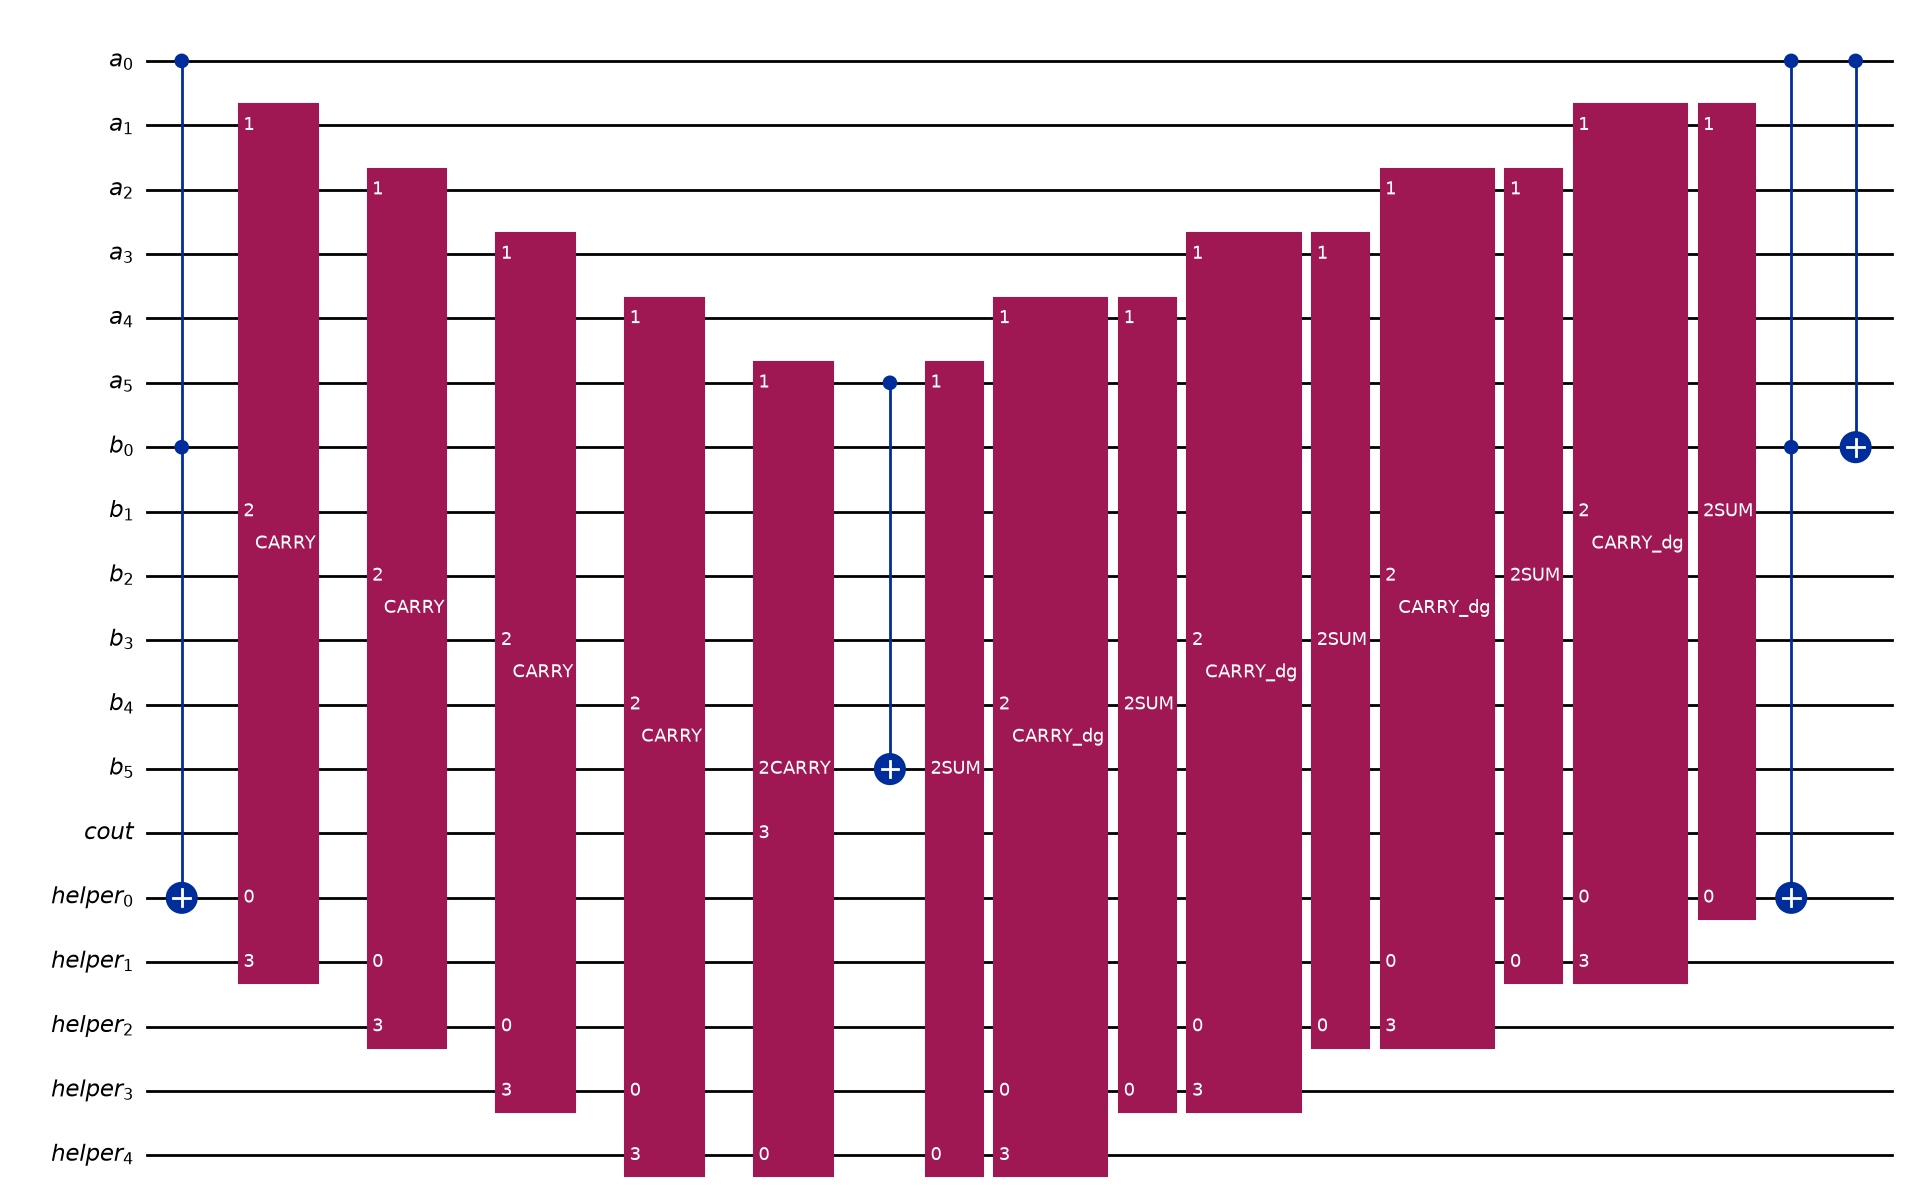

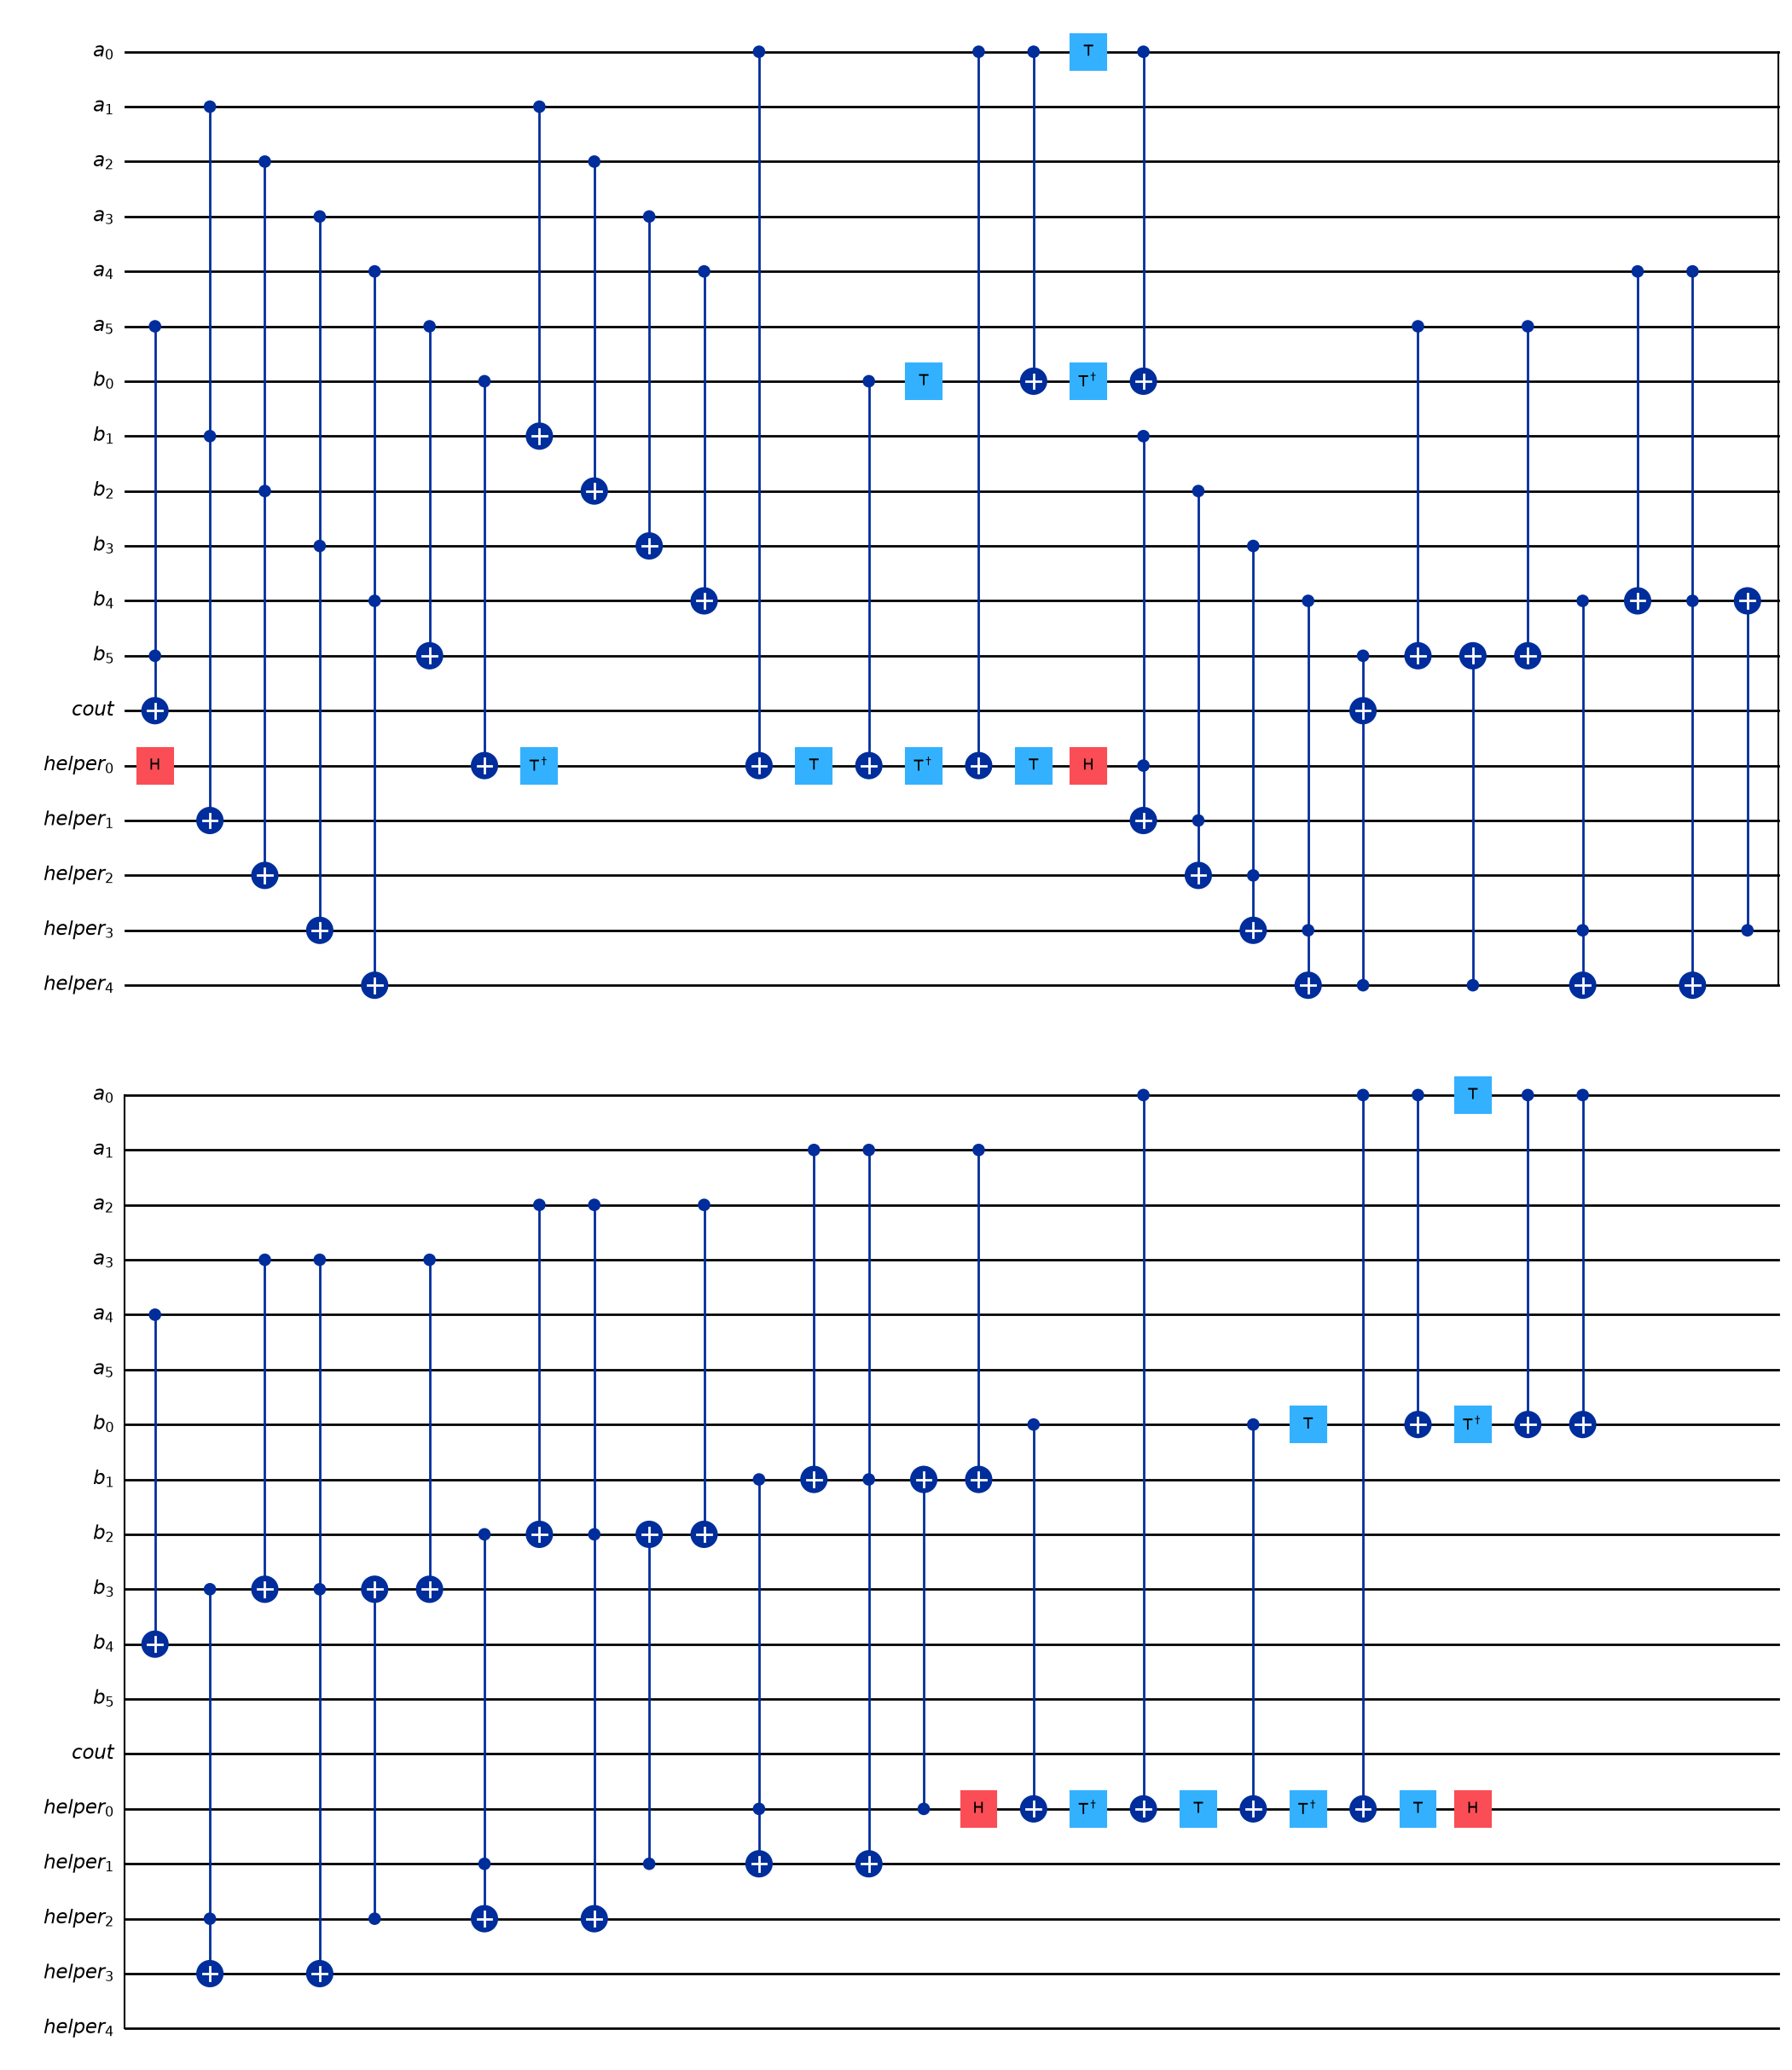

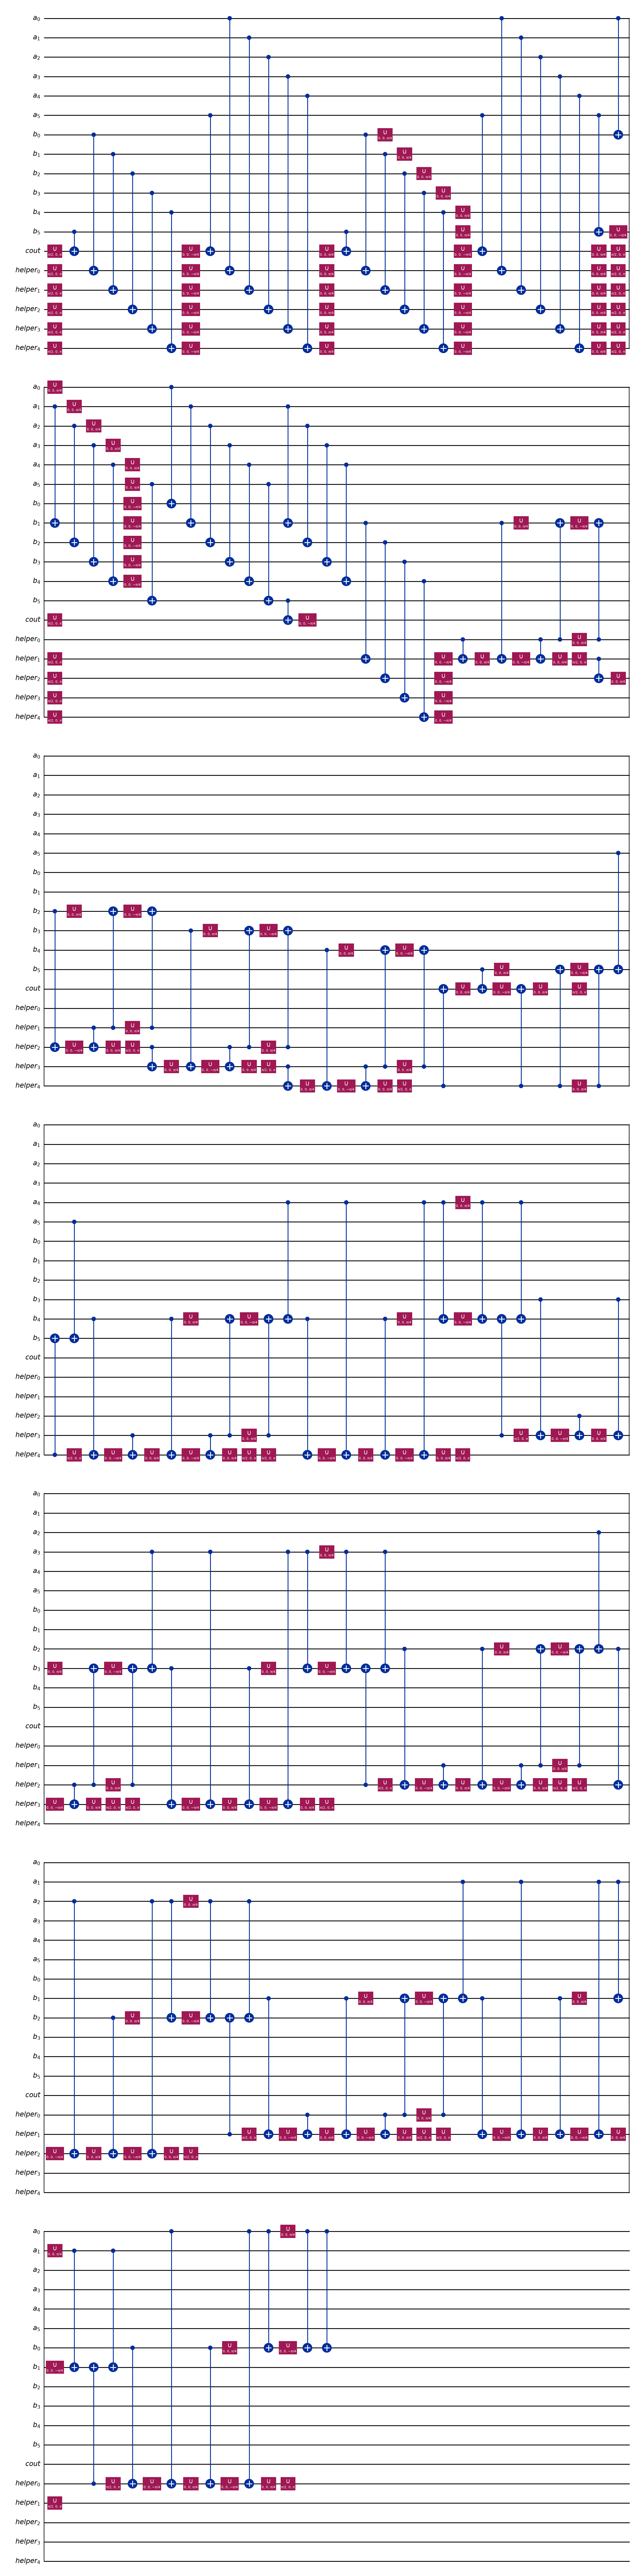

In [ ]:
def sum_block() -> QuantumCircuit:
    qc = QuantumCircuit(3, name="SUM")
    qc.cx(0, 2)
    qc.cx(1, 2)
    return qc

def carry_block() -> QuantumCircuit:
    qc = QuantumCircuit(4, name="CARRY")
    qc.ccx(1, 2, 3)
    qc.cx(1, 2)
    qc.ccx(0, 2, 3)
    return qc

def carry_inverse_block() -> QuantumCircuit:
    qc = QuantumCircuit(4, name="CARRY_dg")
    qc.ccx(0, 2, 3)
    qc.cx(1, 2)
    qc.ccx(1, 2, 3)
    return qc

def assemble_vbe(n: int) -> QuantumCircuit:
    if n < 1:
        raise ValueError("n must be at least 1.")

    a = QuantumRegister(n, "a")
    b = QuantumRegister(n, "b")
    cout = QuantumRegister(1, "cout")

    if n == 1:
        qc = QuantumCircuit(a, b, cout, name="VBE_Scratch_1bit")
        qc.ccx(a[0], b[0], cout[0])
        qc.cx(a[0], b[0])
        return qc

    helper = QuantumRegister(n - 1, "helper")
    qc = QuantumCircuit(a, b, cout, helper, name=f"VBE_Scratch_{n}bit")

    qc.ccx(a[0], b[0], helper[0]) #

    for i in range(1, n): #
        carry_in = helper[i - 1]
        carry_out = cout[0] if i == n - 1 else helper[i]
        qc.append(carry_block(), [carry_in, a[i], b[i], carry_out])

    qc.cx(a[n - 1], b[n - 1]) #
    qc.append(sum_block(), [helper[n - 2], a[n - 1], b[n - 1]]) #

    for i in range(n - 2, 0, -1): #
        qc.append(
            carry_inverse_block(),
            [helper[i - 1], a[i], b[i], helper[i]],
        )
        qc.append(sum_block(), [helper[i - 1], a[i], b[i]])

    qc.ccx(a[0], b[0], helper[0]) #
    qc.cx(a[0], b[0]) #

    return qc

def verify(a: int, b: int):
    n = max(1, a.bit_length(), b.bit_length())
    circuit = assemble_vbe(n)
    result = run_circuit(circuit, {"a": a, "b": b})

    total = result["b"] + (result["cout"] << n)

    assert result["a"] == a
    assert total == a + b
    if "helper" in result:
        assert result["helper"] == 0

    binary_result = format(total, f"0{n + 1}b")
    print(f"Result register: {binary_result} (binary) = {total} (decimal)")
    print(f"Verified: {a} + {b} = {total}")
    resource_analysis(circuit)
    return circuit

verify(0, 0)
verify(5, 7)
verify(8, 3)
vbe_example = verify(25, 41)
display(vbe_example.draw("mpl", fold=-1))
# display(vbe_example.decompose().draw("mpl", fold=-1))
# display(vbe_example.decompose(reps=1).draw("mpl", fold=30))
# primitive = transpile(vbe_example, basis_gates=["u", "cx"], optimization_level=0)
# display(primitive.draw("mpl", fold=30))

## Step 1b. MAJ/UMA ripple-carry adder

Implement a reversible CDKM-style binary adder from majority (MAJ) and unmajority-and-add (UMA) blocks. Assertions check arithmetic output and ancilla cleanup.

### Analytical resource expressions

- **Gate count:** $G(n)=34n+1$
- **Circuit depth:** $D(n)=24n+2$
- **Logical qubits:** $Q(n)=2n+2$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

Result register: 00 (binary) = 0 (decimal)
Verified: 0 + 0 = 0
Resource analysis: 1Q gates=18, 2Q gates=17, total=35, depth=26, qubits=4
Result register: 1100 (binary) = 12 (decimal)
Verified: 5 + 7 = 12
Resource analysis: 1Q gates=54, 2Q gates=49, total=103, depth=74, qubits=8
Result register: 10001111 (binary) = 143 (decimal)
Verified: 99 + 44 = 143
Resource analysis: 1Q gates=126, 2Q gates=113, total=239, depth=170, qubits=16
Result register: 11111111110 (binary) = 2046 (decimal)
Verified: 1023 + 1023 = 2046
Resource analysis: 1Q gates=180, 2Q gates=161, total=341, depth=242, qubits=22


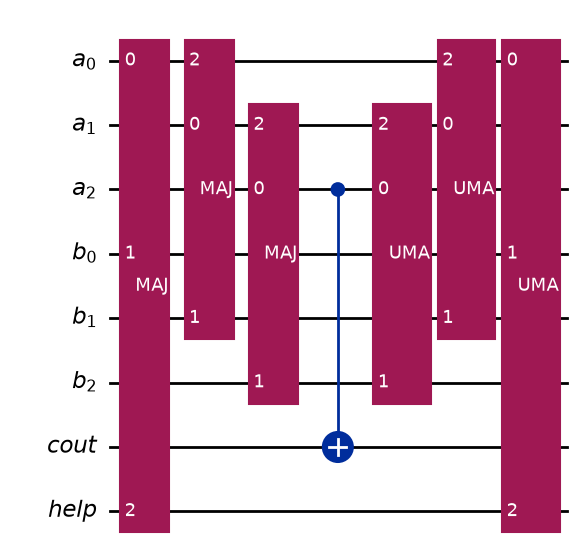

In [17]:
def maj_block() -> QuantumCircuit:
    qc = QuantumCircuit(3, name="MAJ")
    qc.cx(0, 1)
    qc.cx(0, 2)
    qc.ccx(2, 1, 0)
    return qc

def uma_block() -> QuantumCircuit:
    qc = QuantumCircuit(3, name="UMA")
    qc.ccx(2, 1, 0)
    qc.cx(0, 2)
    qc.cx(2, 1)
    return qc

def assemble_cdkm(n: int) -> QuantumCircuit:
    if n < 1:
        raise ValueError("n must be at least 1.")

    a = QuantumRegister(n, "a")
    b = QuantumRegister(n, "b")
    cout = QuantumRegister(1, "cout")
    help_reg = QuantumRegister(1, "help")

    qc = QuantumCircuit(a, b, cout, help_reg, name=f"CDKM_Scratch_{n}bit")

    qc.append(maj_block(), [a[0], b[0], help_reg[0]])

    for i in range(1, n):
        qc.append(maj_block(), [a[i], b[i], a[i - 1]])

    qc.cx(a[n - 1], cout[0])

    for i in range(n - 1, 0, -1):
        qc.append(uma_block(), [a[i], b[i], a[i - 1]])

    qc.append(uma_block(), [a[0], b[0], help_reg[0]])

    return qc

def verify(a: int, b: int):
    n = max(1, a.bit_length(), b.bit_length())
    circuit = assemble_cdkm(n)
    result = run_circuit(circuit, {"a": a, "b": b})

    total = result["b"] + (result["cout"] << n)

    assert result["a"] == a
    assert total == a + b
    assert result["help"] == 0

    binary_result = format(total, f"0{n + 1}b")
    print(f"Result register: {binary_result} (binary) = {total} (decimal)")
    print(f"Verified: {a} + {b} = {total}")
    resource_analysis(circuit)
    return circuit

verify(0, 0)
cdkm_example = verify(5, 7)
verify(99, 44)
verify(1023, 1023)
display(cdkm_example.draw("mpl", fold=-1))
#display(cdkm_example.decompose().draw("mpl", fold=-1))

## Step 2a. Qiskit CDKM adder

Verify the library `CDKMRippleCarryAdder` against representative classical sums using the same measurement and resource-counting functions.

### Analytical resource expressions

- **Gate count:** $G(n)=34n+1$
- **Circuit depth:** $D(n)=24n+2$
- **Logical qubits:** $Q(n)=2n+2$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

In [19]:
def verify(a: int, b: int):
    n = max(1, a.bit_length(), b.bit_length())
    circuit = CDKMRippleCarryAdder(num_state_qubits=n, kind="half")
    result = run_circuit(circuit, {"a": a, "b": b})

    total = result["b"] + (result["cout"] << n)

    assert result["a"] == a
    assert total == a + b
    assert result["help"] == 0

    binary_result = format(total, f"0{n + 1}b")
    print(f"Result register: {binary_result} (binary) = {total} (decimal)")
    print(f"Verified: {a} + {b} = {total}")
    resource_analysis(circuit)
    return circuit

verify(0, 0)
verify(5, 7)
verify(99, 44)
verify(1023, 1023)

#display(CDKMRippleCarryAdder(3, kind="half").decompose(reps=2).draw("mpl", fold=-1))

Result register: 00 (binary) = 0 (decimal)
Verified: 0 + 0 = 0
Resource analysis: 1Q gates=18, 2Q gates=17, total=35, depth=26, qubits=4
Result register: 1100 (binary) = 12 (decimal)
Verified: 5 + 7 = 12
Resource analysis: 1Q gates=54, 2Q gates=49, total=103, depth=74, qubits=8
Result register: 10001111 (binary) = 143 (decimal)
Verified: 99 + 44 = 143
Resource analysis: 1Q gates=126, 2Q gates=113, total=239, depth=170, qubits=16
Result register: 11111111110 (binary) = 2046 (decimal)
Verified: 1023 + 1023 = 2046
Resource analysis: 1Q gates=180, 2Q gates=161, total=341, depth=242, qubits=22


## Step 2b. Qiskit VBE adder

Verify the library `VBERippleCarryAdder` and compare its resource scaling with the CDKM implementation.

### Analytical resource expressions

- **Gate count:** $G(n)=64n-63$ for $n\geq 2$; $G(1)=16$
- **Circuit depth:** $D(n)=30n-24$ for $n\geq 2$; $D(1)=12$
- **Logical qubits:** $Q(n)=3n$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

In [21]:
def verify(a: int, b: int):
    n = max(1, a.bit_length(), b.bit_length())
    circuit = VBERippleCarryAdder(n, kind="half")
    result = run_circuit(circuit, {"a": a, "b": b})

    total = result["b"] + (result["cout"] << n)

    assert result["a"] == a
    assert total == a + b
    if "helper" in result:
        assert result["helper"] == 0

    binary_result = format(total, f"0{n + 1}b")
    print(f"Result register: {binary_result} (binary) = {total} (decimal)")
    print(f"Verified: {a} + {b} = {total}")
    resource_analysis(circuit)
    return circuit

verify(0, 0)
verify(5, 7)
verify(8, 3)
verify(25, 41)

#display(VBERippleCarryAdder(3, kind="half").decompose(reps=2).draw("mpl", fold=-1))

Result register: 00 (binary) = 0 (decimal)
Verified: 0 + 0 = 0
Resource analysis: 1Q gates=9, 2Q gates=7, total=16, depth=12, qubits=3
Result register: 1100 (binary) = 12 (decimal)
Verified: 5 + 7 = 12
Resource analysis: 1Q gates=72, 2Q gates=57, total=129, depth=68, qubits=9
Result register: 01011 (binary) = 11 (decimal)
Verified: 8 + 3 = 11
Resource analysis: 1Q gates=108, 2Q gates=85, total=193, depth=99, qubits=12
Result register: 1000010 (binary) = 66 (decimal)
Verified: 25 + 41 = 66
Resource analysis: 1Q gates=180, 2Q gates=141, total=321, depth=161, qubits=18


## Step 3a. CDKM-based modular addition

Compose reversible addition, conditional subtraction, and restoration to compute $(a+b)\bmod N$ on the tested valid-residue inputs. The simulator checks result and register cleanup.

### Analytical resource expressions

- **Gate count:** $G(n)\leq178n+9$
- **Circuit depth:** $D(n)\leq122n+20$
- **Logical qubits:** $Q(n)=3n+3$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

Result register: 0000 (binary) = 0 (decimal)
Verified: (0 + 0) mod 13 = 0
Resource analysis: 1Q gates=362, 2Q gates=357, total=719, depth=494, qubits=15
Result register: 1011 (binary) = 11 (decimal)
Verified: (8 + 3) mod 13 = 11
Resource analysis: 1Q gates=362, 2Q gates=357, total=719, depth=494, qubits=15
Result register: 0100 (binary) = 4 (decimal)
Verified: (8 + 9) mod 13 = 4
Resource analysis: 1Q gates=362, 2Q gates=357, total=719, depth=494, qubits=15
Result register: 0010000 (binary) = 16 (decimal)
Verified: (99 + 44) mod 127 = 16
Resource analysis: 1Q gates=632, 2Q gates=623, total=1255, depth=854, qubits=24


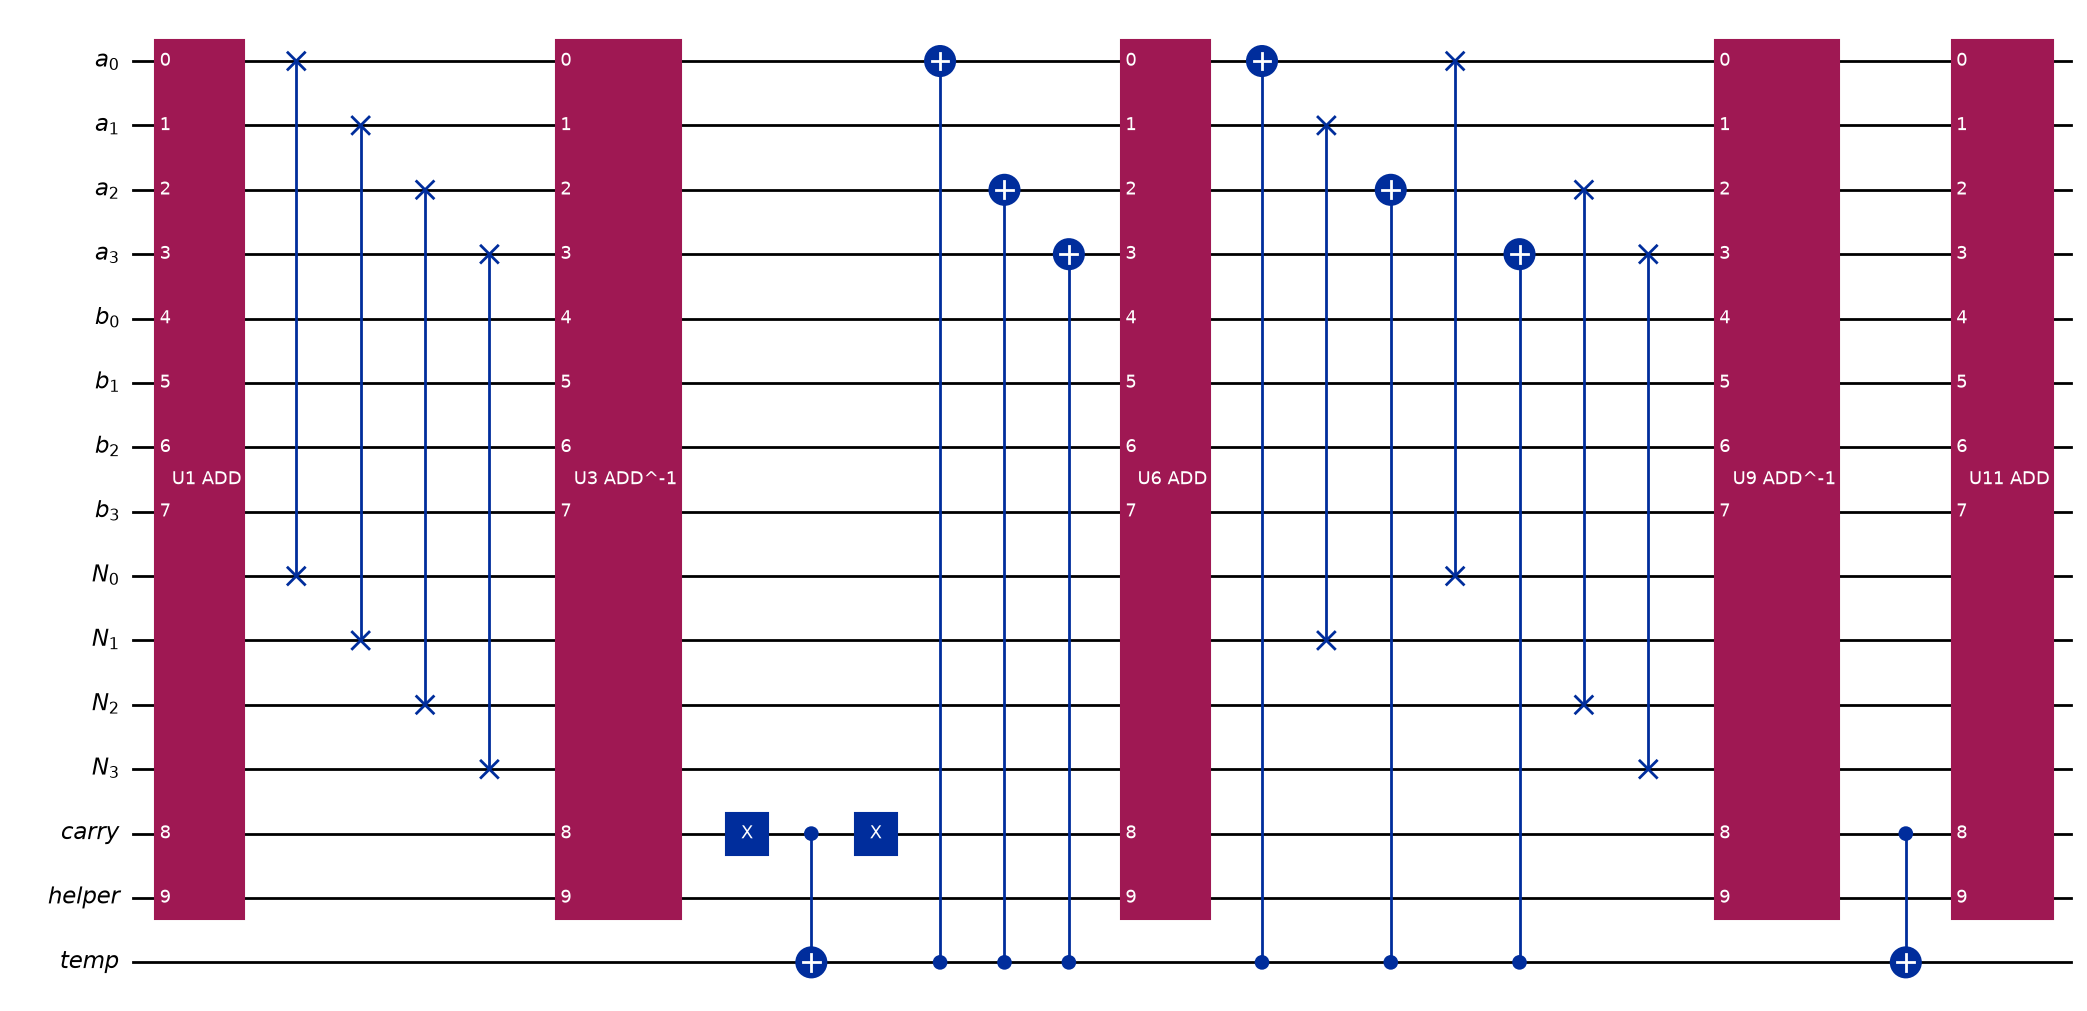

In [29]:
def assemble_modular_adder_cdkm(n: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 0 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 0 < N < 2^n.")

    a = QuantumRegister(n, "a")
    b = QuantumRegister(n, "b")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helper = QuantumRegister(1, "helper")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(a, b, N, carry, helper, temp, name=f"MODADD_CDKM_{n}bit")

    adder = CDKMRippleCarryAdder(num_state_qubits=n, kind="half")
    adder_qargs = lambda x, y: list(x) + list(y) + [carry[0], helper[0]]

    append_circuit(qc, adder, adder_qargs(a, b), label="U1 ADD")

    for i in range(n):
        qc.swap(a[i], N[i])

    append_circuit(qc, adder, adder_qargs(a, b), inverse=True, label="U3 ADD^-1")

    qc.x(carry[0])
    qc.cx(carry[0], temp[0])
    qc.x(carry[0])

    cancel_or_restore_N(qc, temp[0], a, modulus)
    append_circuit(qc, adder, adder_qargs(a, b), label="U6 ADD")
    cancel_or_restore_N(qc, temp[0], a, modulus)

    for i in range(n):
        qc.swap(a[i], N[i])

    append_circuit(qc, adder, adder_qargs(a, b), inverse=True, label="U9 ADD^-1")
    qc.cx(carry[0], temp[0])
    append_circuit(qc, adder, adder_qargs(a, b), label="U11 ADD")

    return qc

def verify(a: int, b: int, N: int):
    n = N.bit_length()
    circuit = assemble_modular_adder_cdkm(n, N)
    result = run_circuit(circuit, {"a": a, "b": b, "N": N})

    expected = (a + b) % N

    assert result["a"] == a
    assert result["b"] == expected
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helper"] == 0
    assert result["temp"] == 0

    binary_result = format(result["b"], f"0{n}b")
    print(f"Result register: {binary_result} (binary) = {result['b']} (decimal)")
    print(f"Verified: ({a} + {b}) mod {N} = {expected}")
    resource_analysis(circuit)
    return circuit

verify(0, 0, 13)
verify(8, 3, 13)
modadd_cdkm = verify(8, 9, 13)
verify(99, 44, 127)
display(modadd_cdkm.draw("mpl", fold=-1))

## Step 3b. VBE-based modular addition

Implement the same modular-arithmetic workflow with VBE adders. The construction uses additional helper qubits for carry propagation.

### Analytical resource expressions

- **Gate count:** $G(n)\leq328n-311$
- **Circuit depth:** $D(n)\leq152n-110$
- **Logical qubits:** $Q(n)=4n+1$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. For this displayed construction, the gate and depth expressions scale as $O(n)$, while the number of qubits also scales as $O(n)$.

Result register: 0000 (binary) = 0 (decimal)
Verified: (0 + 0) mod 13 = 0
Resource analysis: 1Q gates=542, 2Q gates=457, total=999, depth=502, qubits=17
Result register: 1011 (binary) = 11 (decimal)
Verified: (8 + 3) mod 13 = 11
Resource analysis: 1Q gates=542, 2Q gates=457, total=999, depth=502, qubits=17
Result register: 0100 (binary) = 4 (decimal)
Verified: (8 + 9) mod 13 = 4
Resource analysis: 1Q gates=542, 2Q gates=457, total=999, depth=502, qubits=17
Result register: 111001 (binary) = 57 (decimal)
Verified: (40 + 17) mod 61 = 57
Resource analysis: 1Q gates=902, 2Q gates=753, total=1655, depth=820, qubits=25


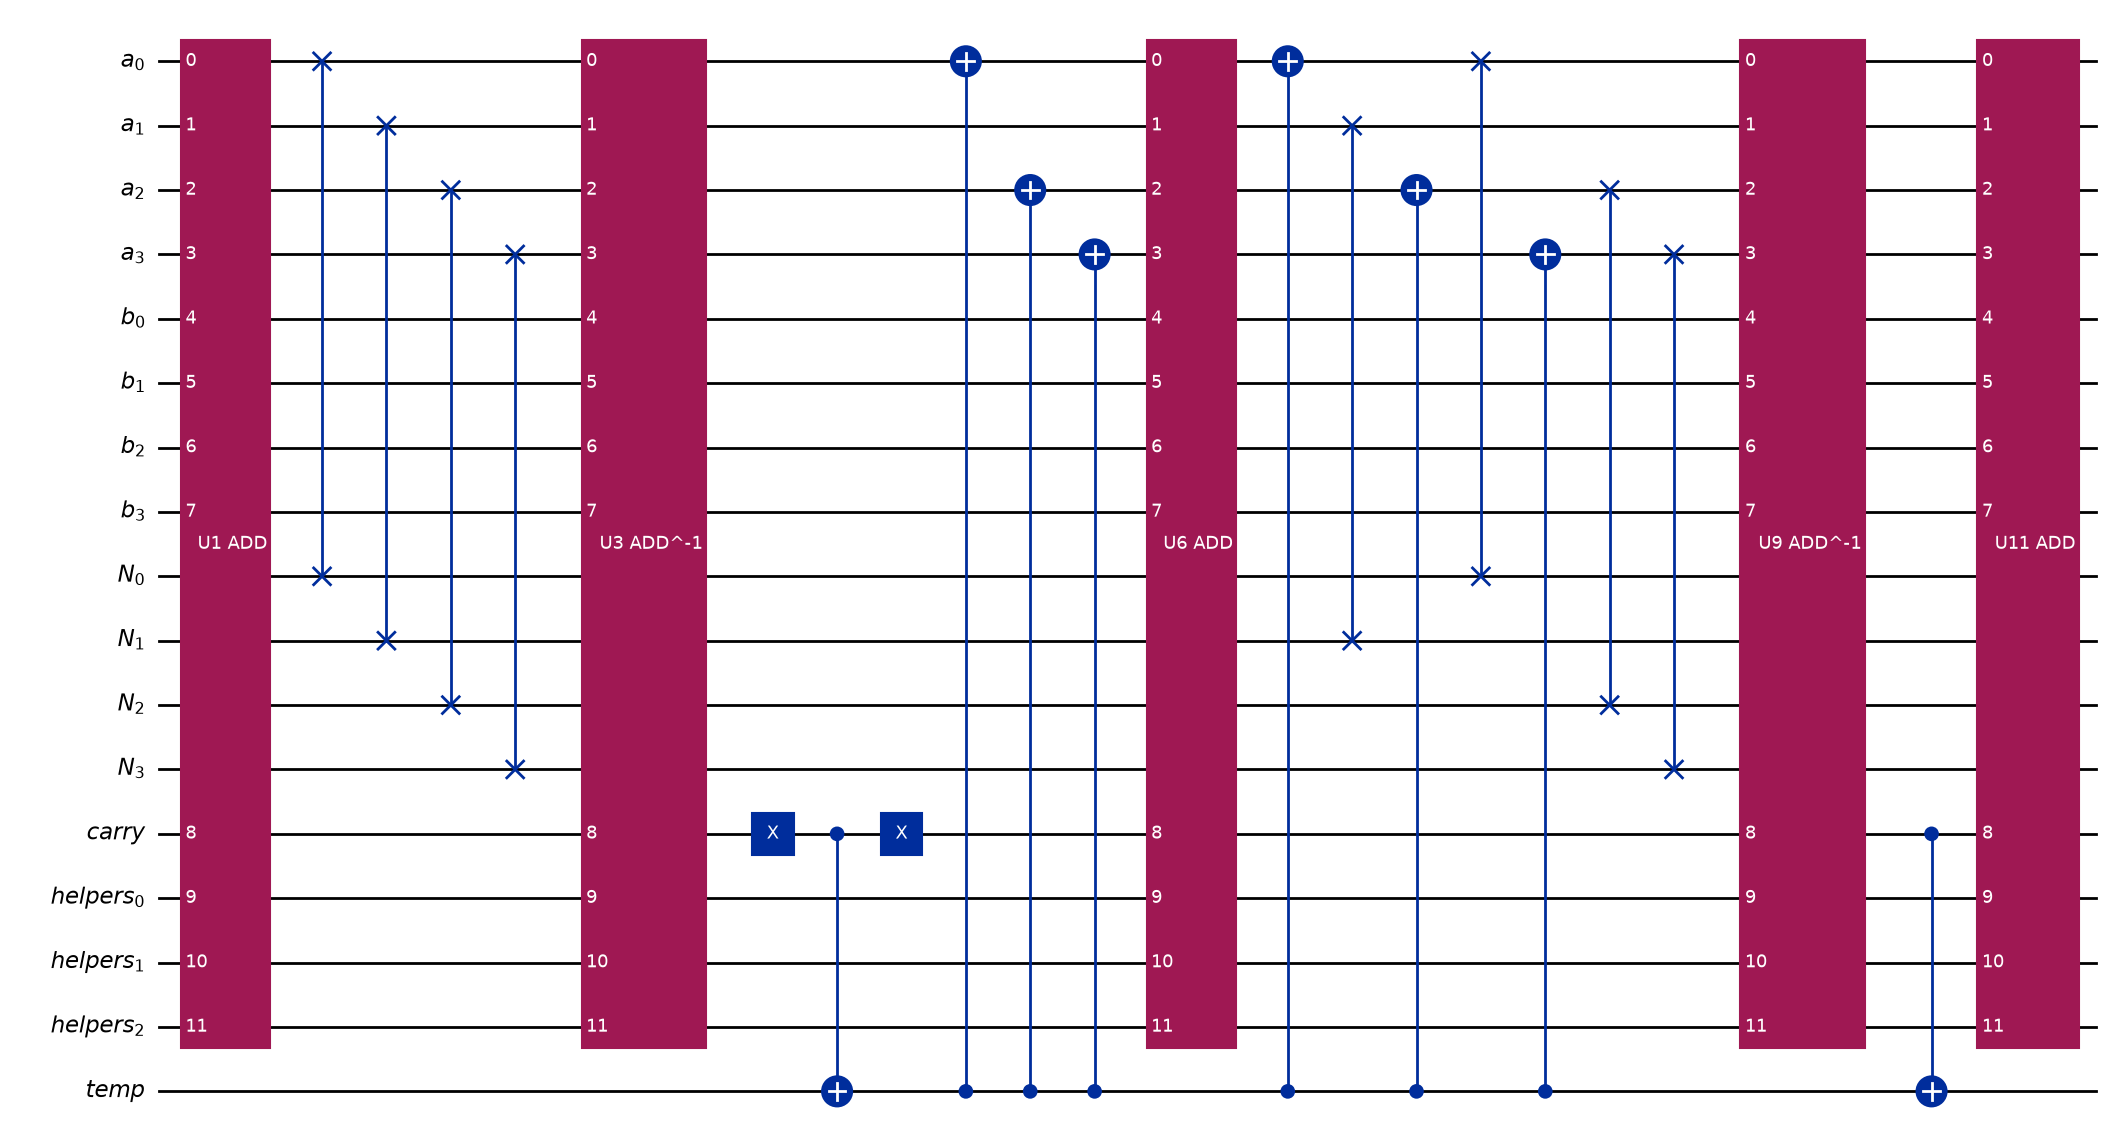

In [7]:
def assemble_modular_adder_vbe(n: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 0 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 0 < N < 2^n.")

    a = QuantumRegister(n, "a")
    b = QuantumRegister(n, "b")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helpers = QuantumRegister(n - 1, "helpers")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(a, b, N, carry, helpers, temp, name=f"MODADD_VBE_{n}bit")

    adder = VBERippleCarryAdder(num_state_qubits=n, kind="half")
    adder_qargs = lambda x, y: list(x) + list(y) + [carry[0]] + list(helpers)

    append_circuit(qc, adder, adder_qargs(a, b), label="U1 ADD")

    for i in range(n):
        qc.swap(a[i], N[i])

    append_circuit(qc, adder, adder_qargs(a, b), inverse=True, label="U3 ADD^-1")

    qc.x(carry[0])
    qc.cx(carry[0], temp[0])
    qc.x(carry[0])

    cancel_or_restore_N(qc, temp[0], a, modulus)
    append_circuit(qc, adder, adder_qargs(a, b), label="U6 ADD")
    cancel_or_restore_N(qc, temp[0], a, modulus)

    for i in range(n):
        qc.swap(a[i], N[i])

    append_circuit(qc, adder, adder_qargs(a, b), inverse=True, label="U9 ADD^-1")
    qc.cx(carry[0], temp[0])
    append_circuit(qc, adder, adder_qargs(a, b), label="U11 ADD")

    return qc

def verify(a: int, b: int, N: int):
    n = N.bit_length()
    circuit = assemble_modular_adder_vbe(n, N)
    result = run_circuit(circuit, {"a": a, "b": b, "N": N})

    expected = (a + b) % N

    assert result["a"] == a
    assert result["b"] == expected
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helpers"] == 0
    assert result["temp"] == 0

    binary_result = format(result["b"], f"0{n}b")
    print(f"Result register: {binary_result} (binary) = {result['b']} (decimal)")
    print(f"Verified: ({a} + {b}) mod {N} = {expected}")
    resource_analysis(circuit)
    return circuit

verify(0, 0, 13)
verify(8, 3, 13)
modadd_vbe = verify(8, 9, 13)
verify(40, 17, 61)
display(modadd_vbe.draw("mpl", fold=-1))

## Step 4a. CDKM-based controlled modular multiplication

For control bit $c$, implement $x\mapsto ax\bmod N$ when $c=1$ and leave $x$ unchanged when $c=0$. The circuit accumulates bit-dependent modular additions and checks work-register cleanup.

### Analytical resource expressions

- **Gate count:** $G(n)\leq208n^2+24n+2$
- **Circuit depth:** $D(n)\leq144n^2+31n+2$
- **Logical qubits:** $Q(n)=4n+4$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. The displayed construction has quadratic resource expressions for gates and depth and linear qubit scaling.

Result register: 0011 (binary) = 3 (decimal)
Verified: c=0, x=3, a=7, N=15 -> B=3
Resource analysis: 1Q gates=1702, 2Q gates=1604, total=3306, depth=2137, qubits=20
Result register: 0110 (binary) = 6 (decimal)
Verified: c=1, x=3, a=7, N=15 -> B=6
Resource analysis: 1Q gates=1702, 2Q gates=1604, total=3306, depth=2137, qubits=20
Result register: 1001 (binary) = 9 (decimal)
Verified: c=1, x=8, a=3, N=15 -> B=9
Resource analysis: 1Q gates=1630, 2Q gates=1556, total=3186, depth=2067, qubits=20
Result register: 100010 (binary) = 34 (decimal)
Verified: c=1, x=44, a=59, N=61 -> B=34
Resource analysis: 1Q gates=3758, 2Q gates=3534, total=7292, depth=4725, qubits=28


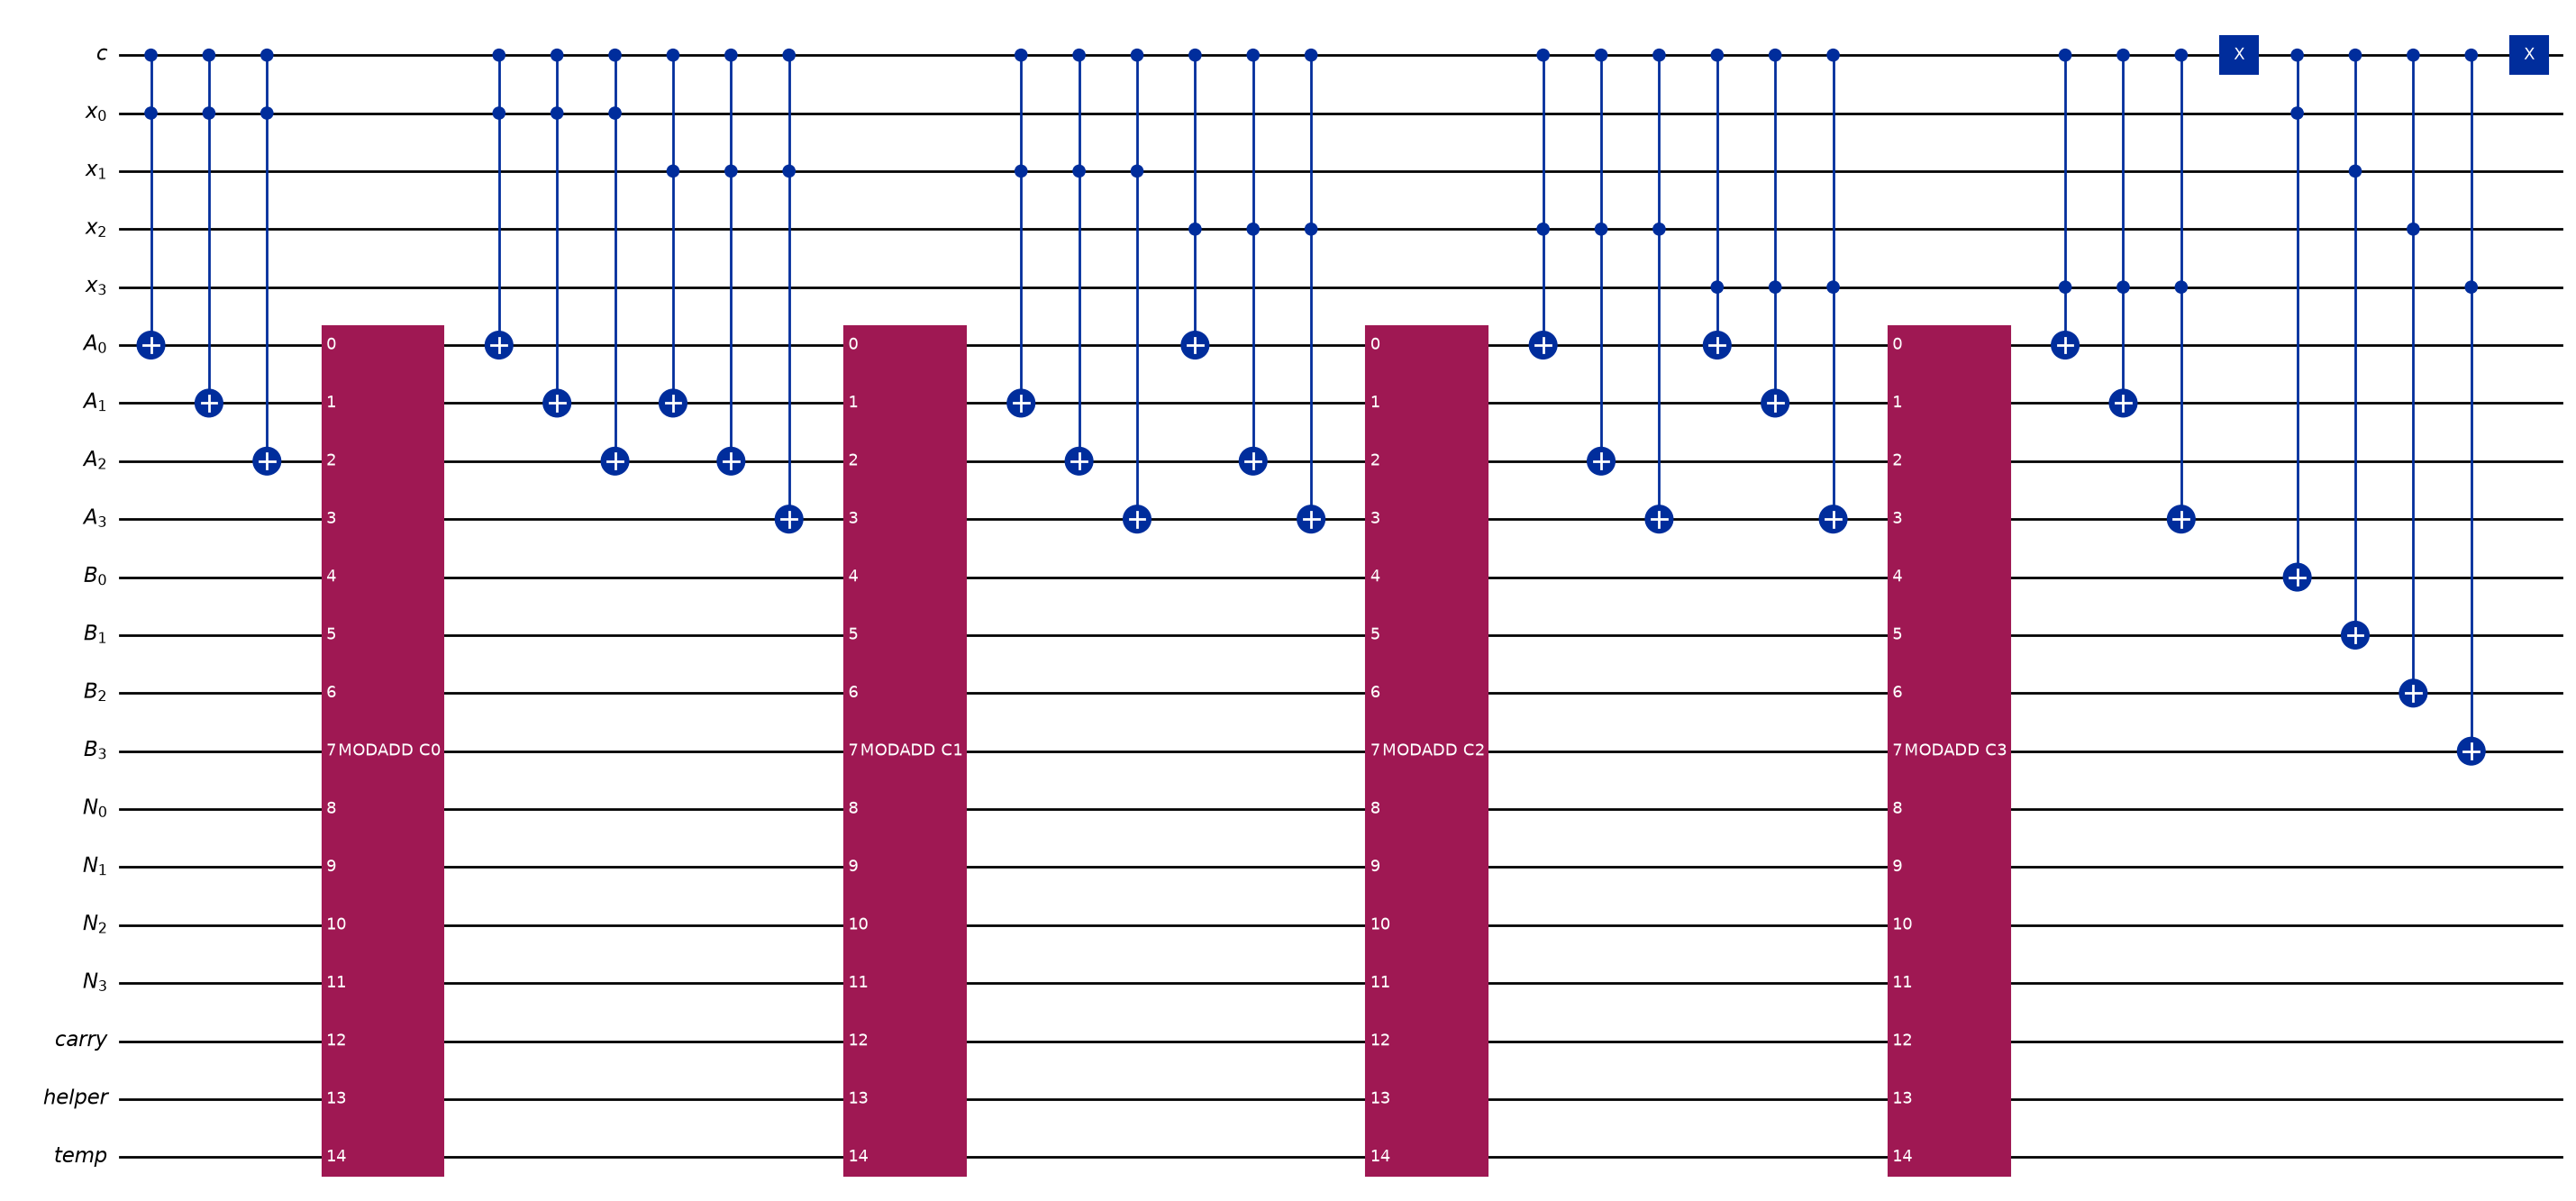

In [8]:
def assemble_cmodmult_cdkm(n: int, multiplier: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 0 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 0 < N < 2^n.")

    a_mod = multiplier % modulus

    c = QuantumRegister(1, "c")
    x = QuantumRegister(n, "x")
    A = QuantumRegister(n, "A")
    B = QuantumRegister(n, "B")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helper = QuantumRegister(1, "helper")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(
        c, x, A, B, N, carry, helper, temp,
        name=f"CMODMULT_CDKM_{n}bit"
    )

    modadd = assemble_modular_adder_cdkm(n, modulus)

    modadd_qargs = (
        list(A) + list(B) + list(N)
        + [carry[0], helper[0], temp[0]]
    )

    for k in range(n):
        C_k = (a_mod * (1 << k)) % modulus
        load_Ck(qc, c[0], x[k], A, C_k)
        append_circuit(qc, modadd, modadd_qargs, label=f"MODADD C{k}")
        load_Ck(qc, c[0], x[k], A, C_k)

    qc.x(c[0])

    for i in range(n):
        qc.ccx(c[0], x[i], B[i])
    qc.x(c[0])
    
    return qc

def verify(c: int, x: int, a: int, N: int):
    n = N.bit_length()
    circuit = assemble_cmodmult_cdkm(n, a, N)
    result = run_circuit(circuit, {"c": c, "x": x, "N": N})
    expected = (a * x) % N if c == 1 else x

    assert result["c"] == c
    assert result["x"] == x
    assert result["A"] == 0
    assert result["B"] == expected
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helper"] == 0
    assert result["temp"] == 0

    binary_result = format(result["B"], f"0{n}b")

    print(f"Result register: {binary_result} (binary) " f"= {result['B']} (decimal)")
    print(f"Verified: c={c}, x={x}, a={a}, N={N} " f"-> B={expected}")
    resource_analysis(circuit)

    return circuit

verify(0, 3, 7, 15)
cmodmult_cdkm = verify(1, 3, 7, 15)
verify(1, 8, 3, 15)
verify(1, 44, 59, 61)
display(cmodmult_cdkm.draw("mpl", fold=-1))

## Step 4b. VBE-based controlled modular multiplication

Repeat the controlled modular multiplication construction with the VBE modular adder and measure its additional gate and ancilla costs.

### Analytical resource expressions

- **Gate count:** $G(n)\leq358n^2-296n+2$
- **Circuit depth:** $D(n)\leq174n^2-99n+2$
- **Logical qubits:** $Q(n)=5n+2$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. The displayed construction has quadratic resource expressions for gates and depth and linear qubit scaling.

Result register: 0011 (binary) = 3 (decimal)
Verified: c=0, x=3, a=7, N=15 -> B=3
Resource analysis: 1Q gates=2422, 2Q gates=2004, total=4426, depth=2207, qubits=22
Result register: 0110 (binary) = 6 (decimal)
Verified: c=1, x=3, a=7, N=15 -> B=6
Resource analysis: 1Q gates=2422, 2Q gates=2004, total=4426, depth=2207, qubits=22
Result register: 1001 (binary) = 9 (decimal)
Verified: c=1, x=8, a=3, N=15 -> B=9
Resource analysis: 1Q gates=2350, 2Q gates=1956, total=4306, depth=2123, qubits=22


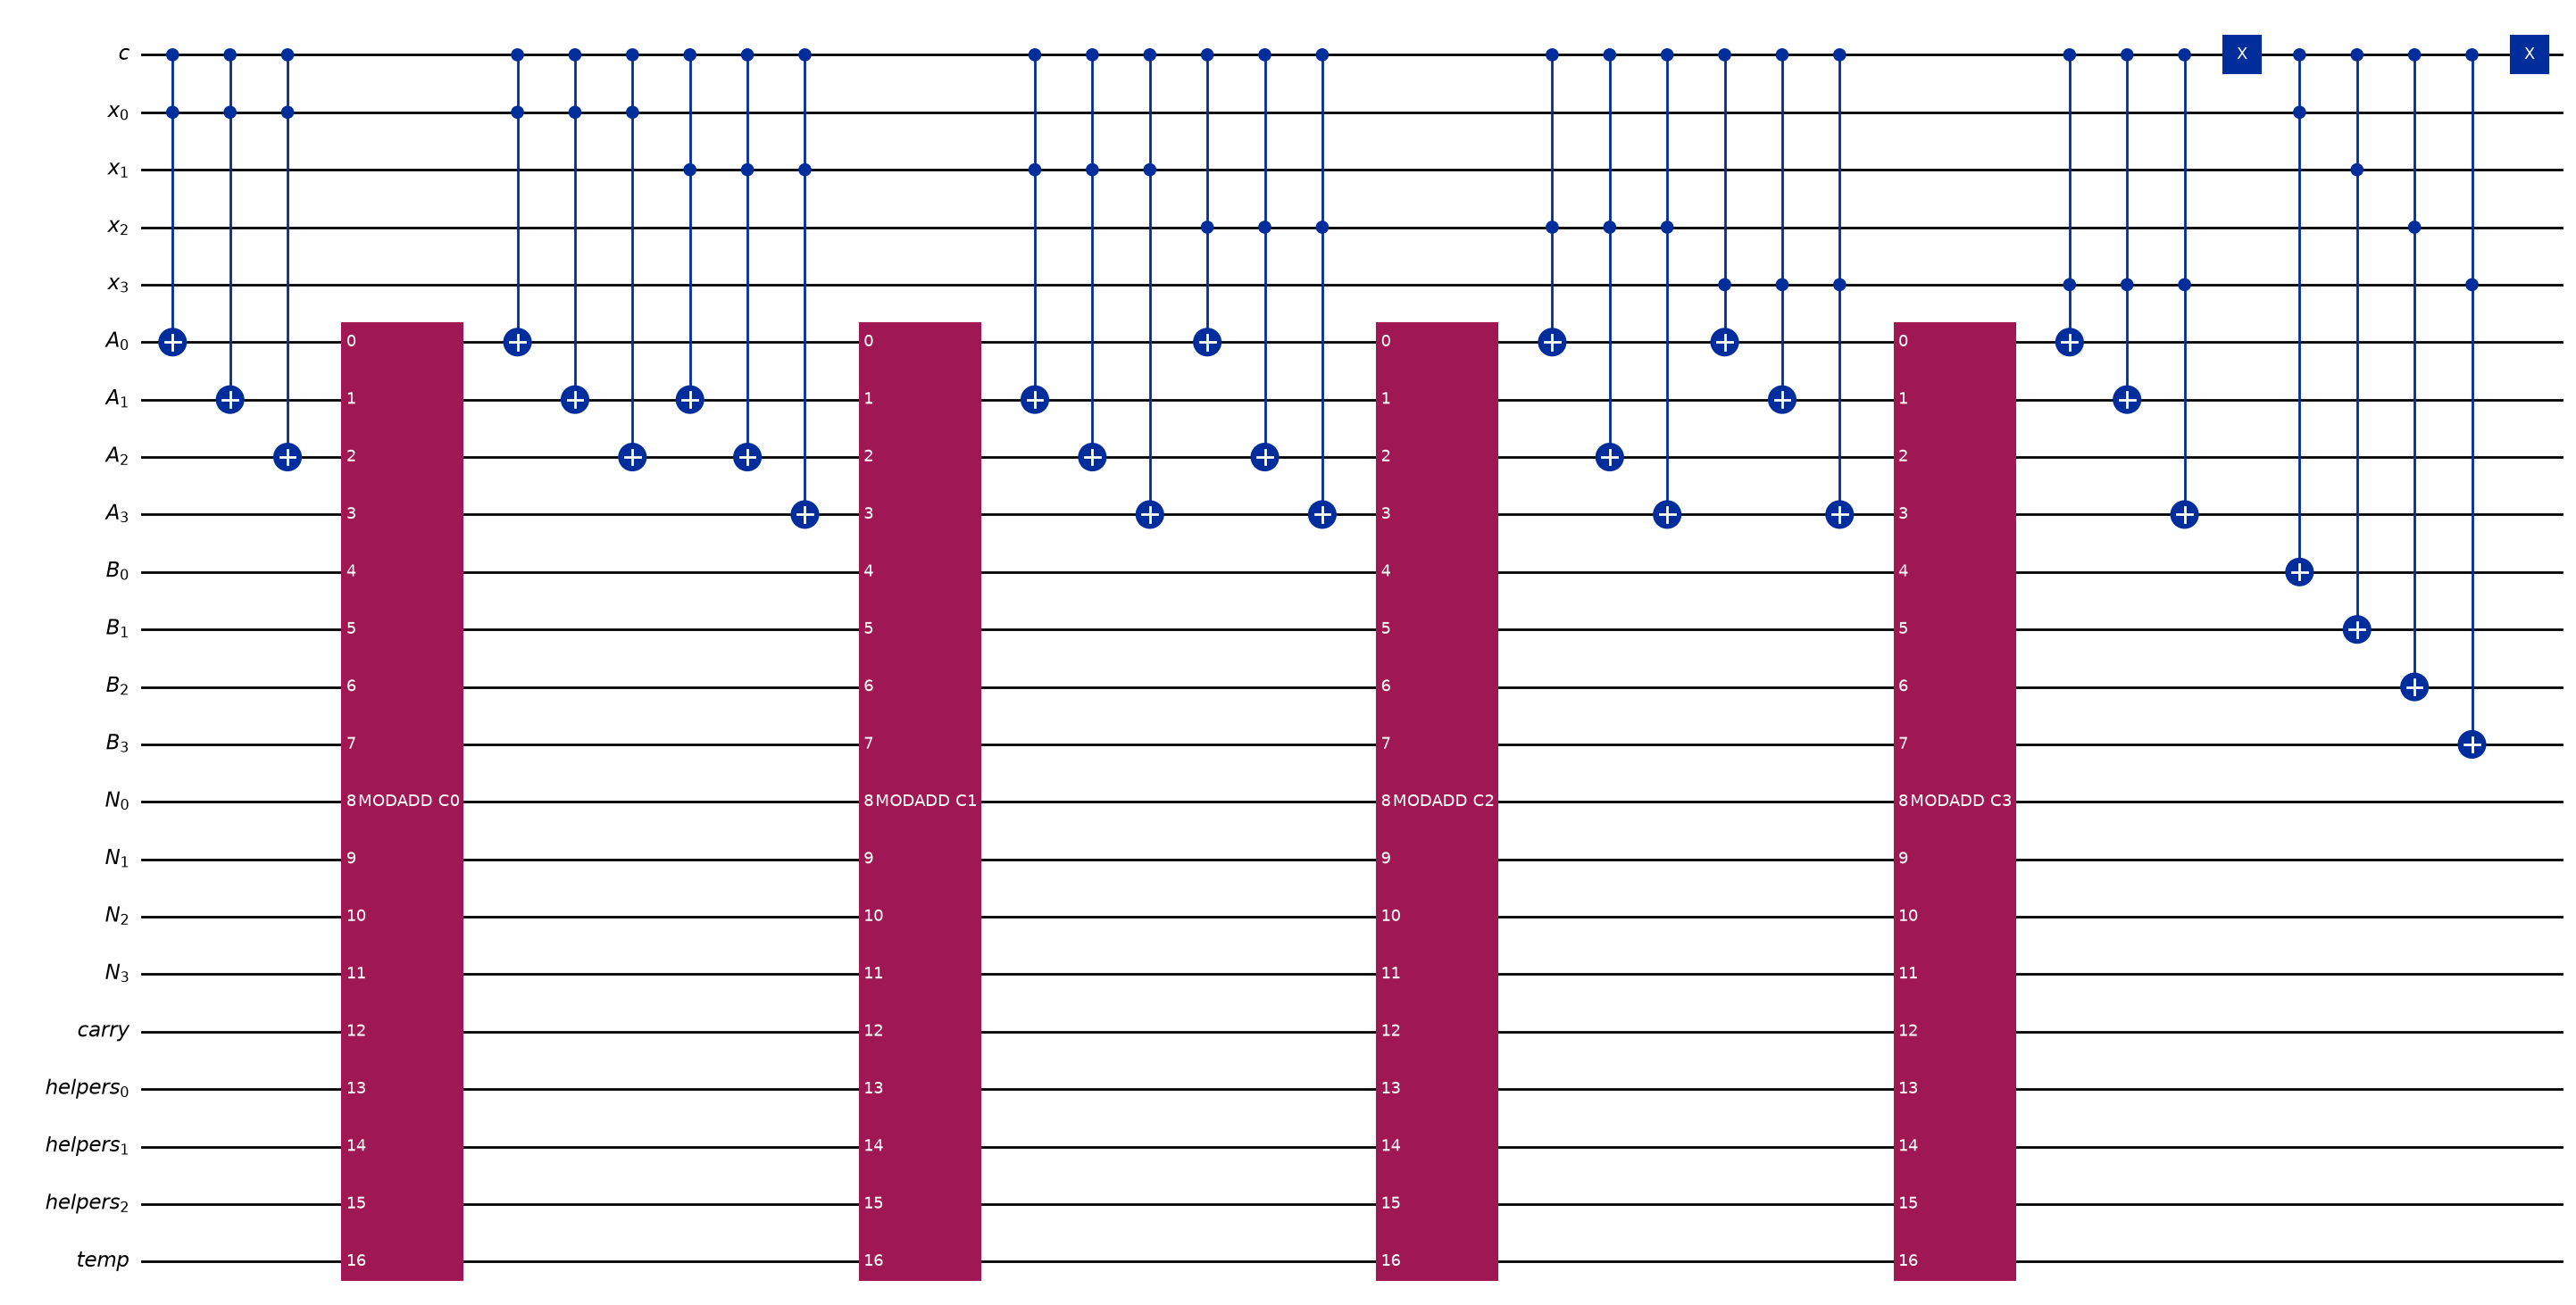

In [9]:
def assemble_cmodmult_vbe(n: int, multiplier: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 0 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 0 < N < 2^n.")

    a_mod = multiplier % modulus

    c = QuantumRegister(1, "c")
    x = QuantumRegister(n, "x")
    A = QuantumRegister(n, "A")
    B = QuantumRegister(n, "B")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helpers = QuantumRegister(n - 1, "helpers")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(
        c, x, A, B, N, carry, helpers, temp,
        name=f"CMODMULT_VBE_{n}bit"
    )

    modadd = assemble_modular_adder_vbe(n, modulus)

    modadd_qargs = (
        list(A) + list(B) + list(N)
        + [carry[0]] + list(helpers) + [temp[0]]
    )

    for k in range(n):
        C_k = (a_mod * (1 << k)) % modulus
        load_Ck(qc, c[0], x[k], A, C_k)
        append_circuit(qc, modadd, modadd_qargs, label=f"MODADD C{k}")
        load_Ck(qc, c[0], x[k], A, C_k)

    qc.x(c[0])

    for i in range(n):
        qc.ccx(c[0], x[i], B[i])

    qc.x(c[0])

    return qc


def verify(c: int, x: int, a: int, N: int):
    n = N.bit_length()

    circuit = assemble_cmodmult_vbe(n, a, N)
    result = run_circuit(circuit, {"c": c, "x": x, "N": N})

    expected = (a * x) % N if c == 1 else x

    assert result["c"] == c
    assert result["x"] == x
    assert result["A"] == 0
    assert result["B"] == expected
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helpers"] == 0
    assert result["temp"] == 0

    binary_result = format(result["B"], f"0{n}b")

    print(f"Result register: {binary_result} (binary) " f"= {result['B']} (decimal)")
    print(f"Verified: c={c}, x={x}, a={a}, N={N} " f"-> B={expected}")
    resource_analysis(circuit)

    return circuit


verify(0, 3, 7, 15)
cmodmult_vbe = verify(1, 3, 7, 15)
verify(1, 8, 3, 15)
display(cmodmult_vbe.draw("mpl", fold=-1))

## Step 5a. CDKM-based modular exponentiation

Compose controlled modular multipliers for the exponent bits to implement $a^x\bmod N$. The example checks $2^7\bmod15=8$ and measures the full arithmetic circuit.

### Analytical resource expressions

- **Gate count:** $G(n)\leq416n^3+51n^2+4n$
- **Circuit depth:** $D(n)\leq288n^3+62n^2+7n$
- **Logical qubits:** $Q(n)=5n+3$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. The displayed construction has cubic gate-count scaling and linear qubit scaling. Depth scaling is cubic for the stated construction/estimate.

Result register: 1000 (binary) = 8 (decimal)
Verified: 2^7 mod 15 = 8
Full MODEXP resource analysis: 1Q gates=12464, 2Q gates=12112, total=24576, depth=16244, qubits=23
A_i constants: [2, 4, 1, 1]


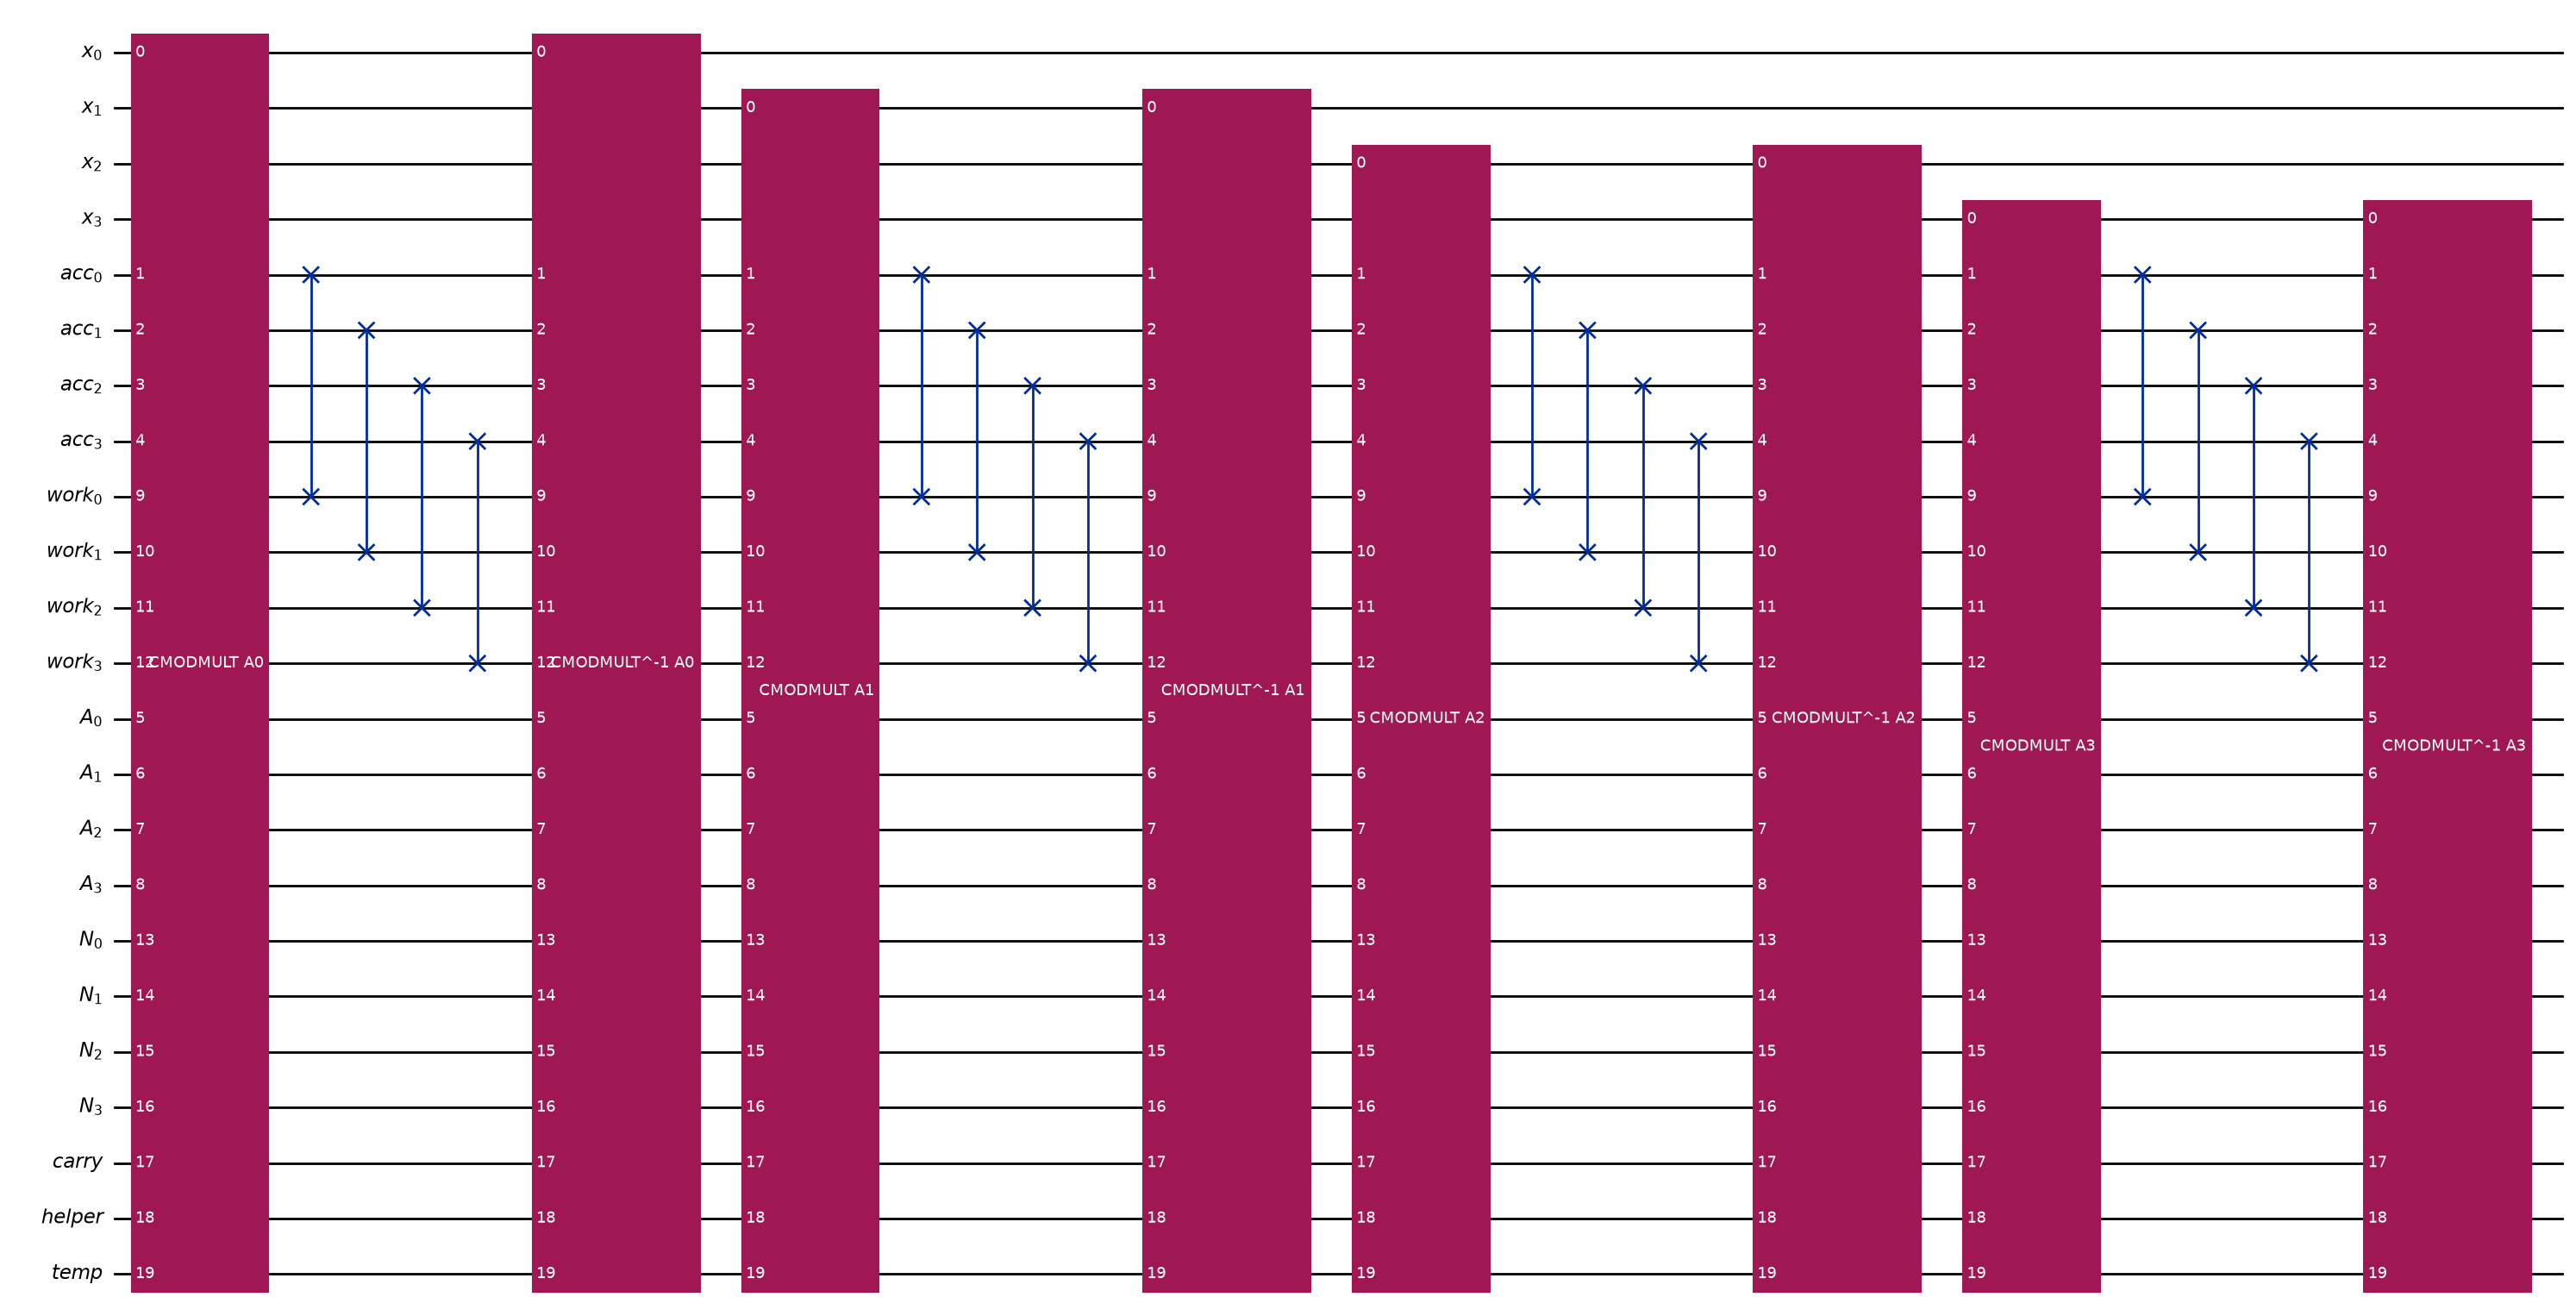

In [23]:
def assemble_modexp_cdkm(n: int, base: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 1 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 1 < N < 2^n.")

    x = QuantumRegister(n, "x")
    acc = QuantumRegister(n, "acc")
    work = QuantumRegister(n, "work")
    A = QuantumRegister(n, "A")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helper = QuantumRegister(1, "helper")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(
        x, acc, work, A, N, carry, helper, temp,
        name=f"MODEXP_CDKM_{n}bit"
    )

    cmod_qargs = (
        lambda control:
        [control]
        + list(acc)
        + list(A)
        + list(work)
        + list(N)
        + [carry[0], helper[0], temp[0]]
    )

    for i in range(n):
        A_i = pow(base, 1 << i, modulus)

        forward = assemble_cmodmult_cdkm(n, A_i, modulus)
        append_circuit(
            qc,
            forward,
            cmod_qargs(x[i]),
            label=f"CMODMULT A{i}",
        )

        for j in range(n):
            qc.swap(acc[j], work[j])

        A_i_inverse = pow(A_i, -1, modulus)

        inverse_multiplier = assemble_cmodmult_cdkm(
            n, A_i_inverse, modulus
        )

        append_circuit(
            qc,
            inverse_multiplier,
            cmod_qargs(x[i]),
            inverse=True,
            label=f"CMODMULT^-1 A{i}",
        )

    return qc


def verify(x: int, a: int, N: int):
    n = N.bit_length()

    circuit = assemble_modexp_cdkm(n, a, N)

    result = run_circuit(circuit, {"x": x, "acc": 1, "N": N})

    expected = pow(a, x, N)

    assert result["x"] == x
    assert result["acc"] == expected
    assert result["work"] == 0
    assert result["A"] == 0
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helper"] == 0
    assert result["temp"] == 0

    binary_result = format(result["acc"], f"0{n}b")

    print(f"Result register: {binary_result} (binary) " f"= {result['acc']} (decimal)")
    print(f"Verified: {a}^{x} mod {N} = {expected}")

    return circuit

modexp_cdkm = verify(7, 2, 15)
modexp_cdkm_resources = resource_analysis(modexp_cdkm, "Full MODEXP resource analysis")
print("A_i constants:", [pow(2, 1 << i, 15) for i in range(4)])
display(modexp_cdkm.draw("mpl", fold=-1))

# pow(5, -1, 15)
# ValueError: base is not invertible for the given modulus

## Step 5b. VBE-based modular exponentiation

Build the corresponding VBE-based construction and verify the same modular-exponentiation example. The depth expression below is an **analytical component-based estimate**, not an independently verified upper bound on full-circuit depth.

### Analytical resource expressions

- **Gate count:** $G(n)\leq716n^3-589n^2+4n$
- **Circuit depth:** $\widehat D(n)=348n^3-198n^2+7n$ (estimated)
- **Logical qubits:** $Q(n)=6n+1$

These formulas are specific to the circuit-building method used here and assume the fixed `u`/`cx` resource-counting convention. The displayed construction has cubic gate-count scaling and linear qubit scaling. Depth scaling is cubic for the stated construction/estimate.

Result register: 1000 (binary) = 8 (decimal)
Verified: 2^7 mod 15 = 8
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2057, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2052, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2053, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2057, qubits=22
Resource analysis: 1Q gates=18224, 2Q gates=15312, total=33536, depth=16444, qubits=25
A_i constants: [2, 4, 1, 1]


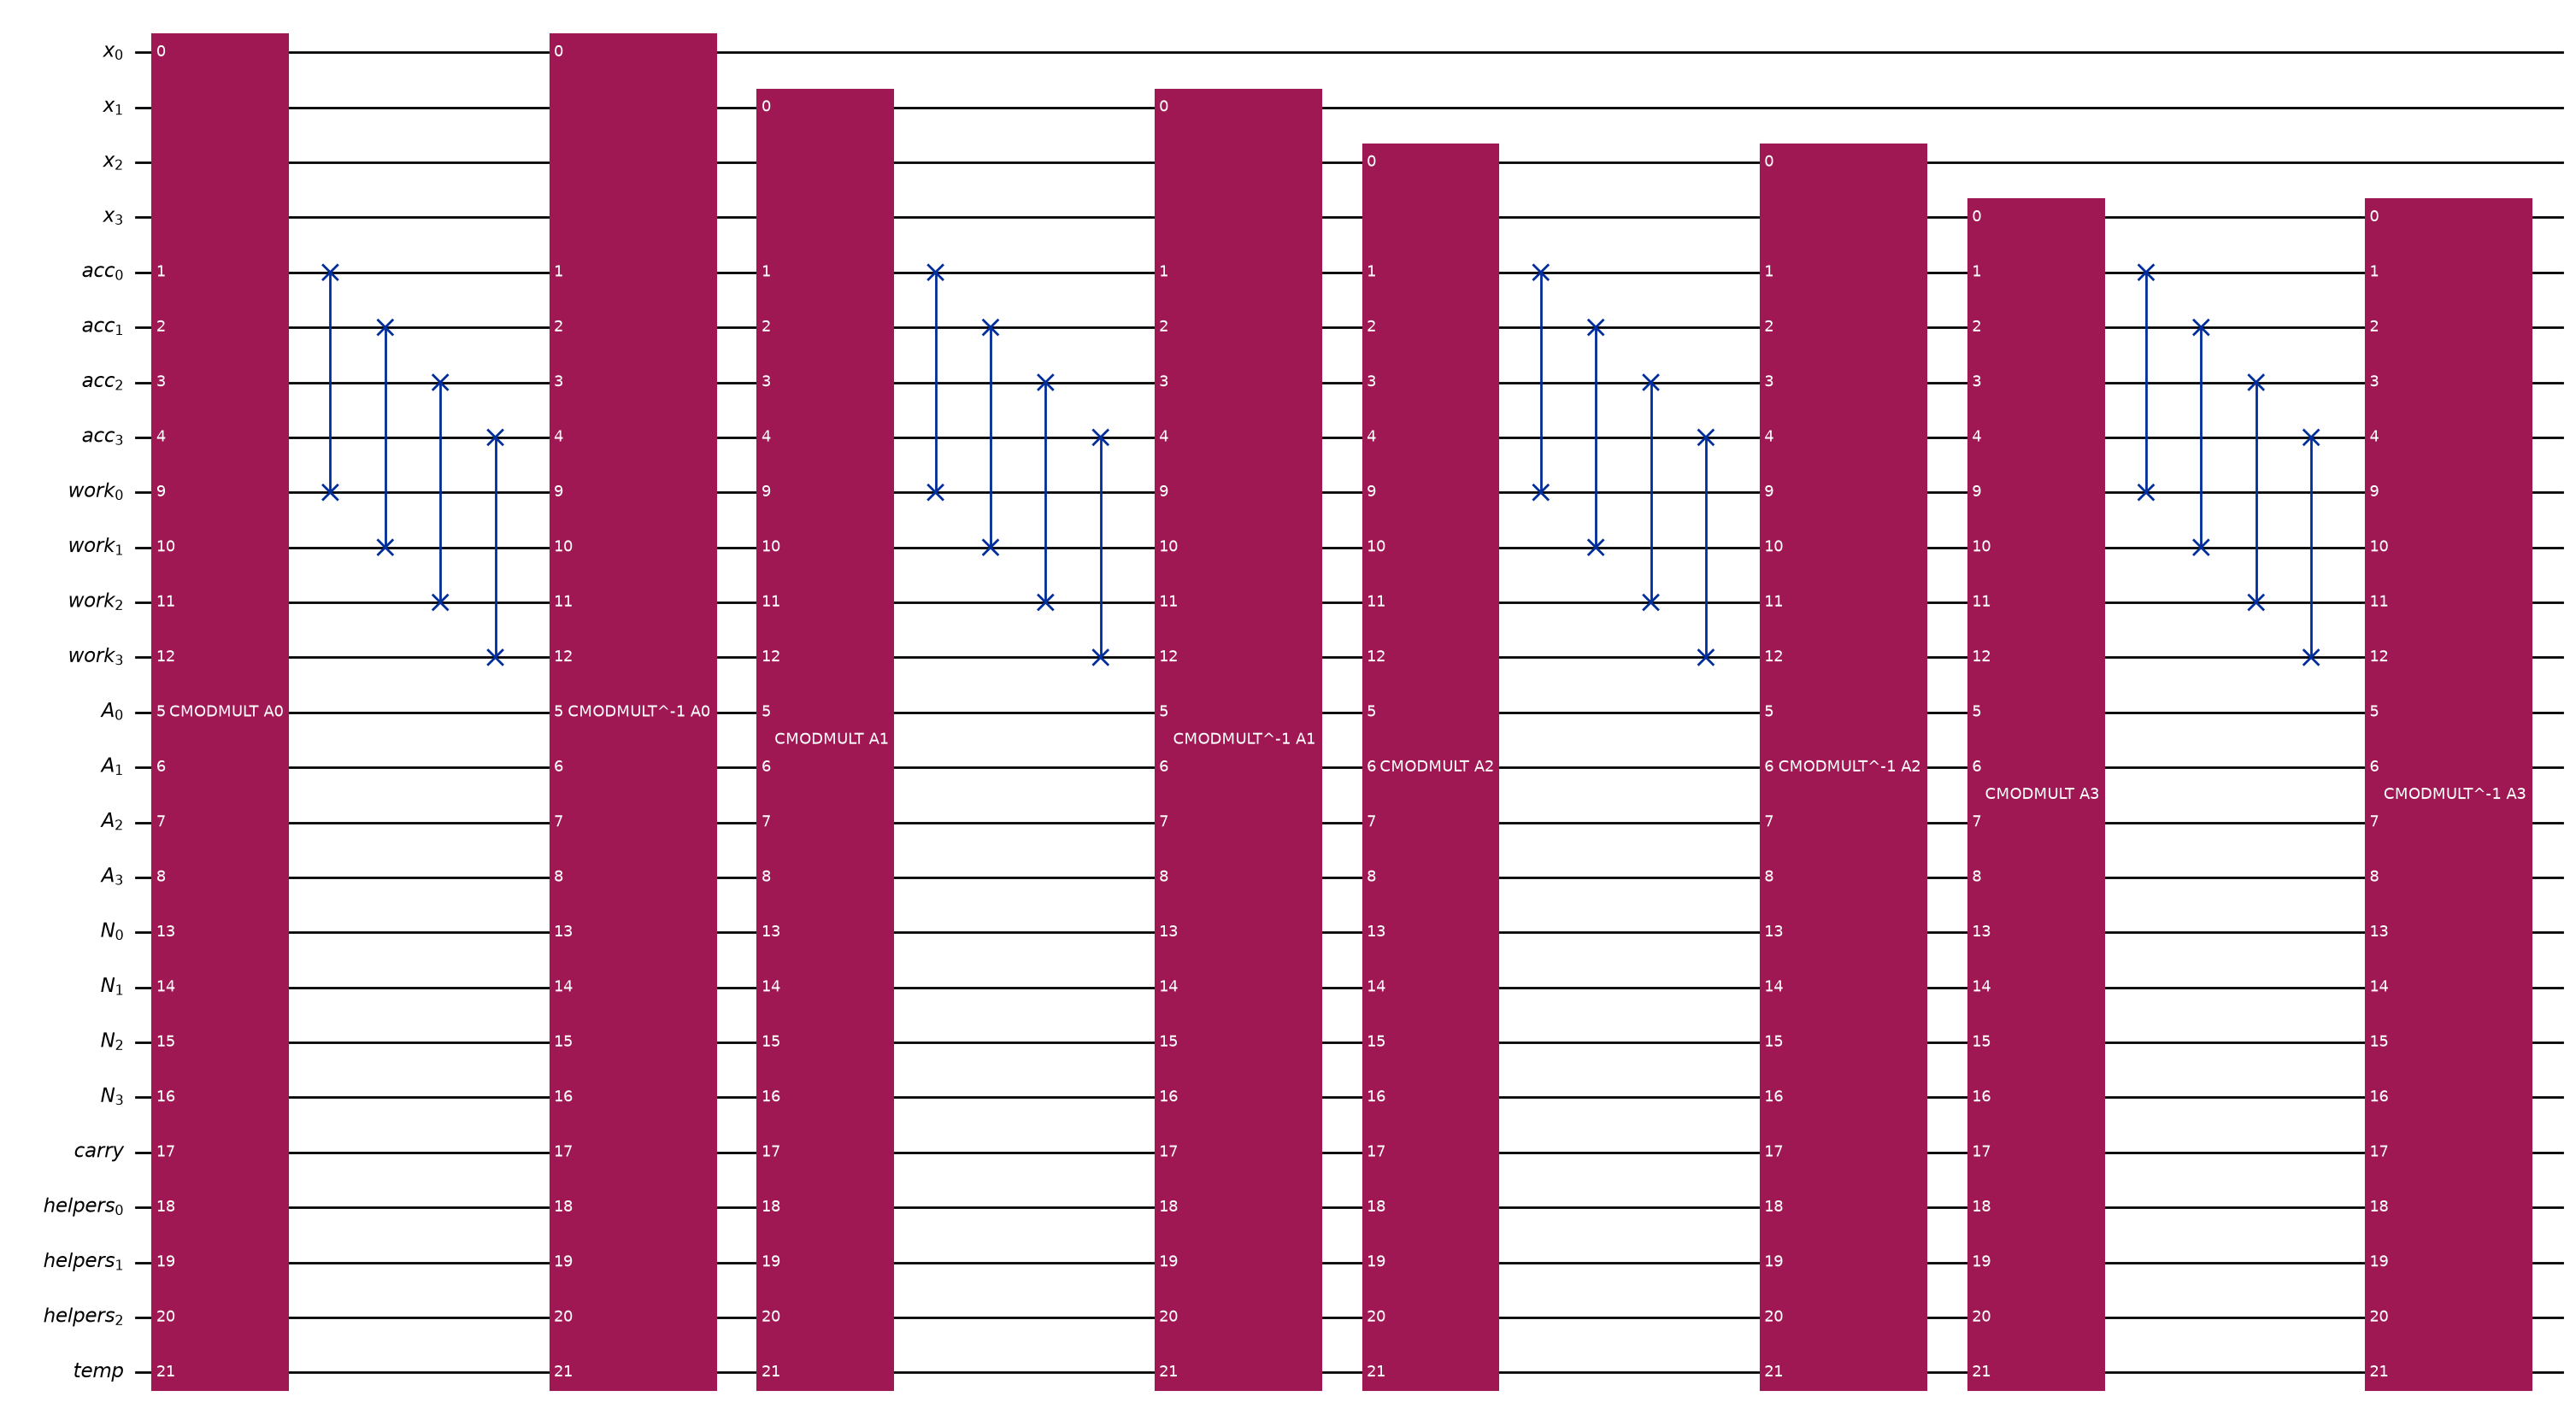

In [11]:
def assemble_modexp_vbe(n: int, base: int, modulus: int) -> QuantumCircuit:
    if n < 2:
        raise ValueError("Use n >= 2.")
    if modulus <= 1 or modulus >= (1 << n):
        raise ValueError("modulus must satisfy 1 < N < 2^n.")

    x = QuantumRegister(n, "x")
    acc = QuantumRegister(n, "acc")
    work = QuantumRegister(n, "work")
    A = QuantumRegister(n, "A")
    N = QuantumRegister(n, "N")
    carry = QuantumRegister(1, "carry")
    helpers = QuantumRegister(n - 1, "helpers")
    temp = QuantumRegister(1, "temp")

    qc = QuantumCircuit(
        x, acc, work, A, N, carry, helpers, temp,
        name=f"MODEXP_VBE_{n}bit"
    )

    cmod_qargs = (
        lambda control:
        [control]
        + list(acc)
        + list(A)
        + list(work)
        + list(N)
        + [carry[0]]
        + list(helpers)
        + [temp[0]]
    )

    for i in range(n):
        A_i = pow(base, 1 << i, modulus)

        forward = assemble_cmodmult_vbe(n, A_i, modulus)

        append_circuit(
            qc,
            forward,
            cmod_qargs(x[i]),
            label=f"CMODMULT A{i}",
        )

        for j in range(n):
            qc.swap(acc[j], work[j])

        A_i_inverse = pow(A_i, -1, modulus)

        inverse_multiplier = assemble_cmodmult_vbe(
            n, A_i_inverse, modulus
        )

        append_circuit(
            qc,
            inverse_multiplier,
            cmod_qargs(x[i]),
            inverse=True,
            label=f"CMODMULT^-1 A{i}",
        )

    return qc


def verify(x: int, a: int, N: int):
    n = N.bit_length()

    circuit = assemble_modexp_vbe(n, a, N)
    result = run_circuit(circuit, {"x": x, "acc": 1, "N": N})
    expected = pow(a, x, N)

    assert result["x"] == x
    assert result["acc"] == expected
    assert result["work"] == 0
    assert result["A"] == 0
    assert result["N"] == N
    assert result["carry"] == 0
    assert result["helpers"] == 0
    assert result["temp"] == 0

    binary_result = format(result["acc"], f"0{n}b")

    print(f"Result register: {binary_result} (binary) " f"= {result['acc']} (decimal)")
    print(f"Verified: {a}^{x} mod {N} = {expected}")
    resources = modeexp_resource_analysis(assemble_cmodmult_vbe, n, a, N, 6 * n + 1)

    return circuit

modexp_vbe = verify(7, 2, 15)
print("A_i constants:", [pow(2, 1 << i, 15) for i in range(4)])
display(modexp_vbe.draw("mpl", fold=-1))

## Step 5c. Comparing CDKM and VBE modular exponentiation

Let $n=\lceil\log_2 N\rceil$ denote the width used for a modulus $N$ in the analytical comparison. The circuits in this notebook allocate their own registers from the passed value of $n$; the verification helpers use `N.bit_length()`.

### Why the resources scale

The construction is nested: a binary adder uses $O(n)$ gates; a modular adder invokes a constant number of adders; each controlled multiplier invokes $n$ modular additions; modular exponentiation invokes controlled multipliers for each of $n$ exponent bits, including inverse operations that reset the work register.

| Metric | CDKM-based modular exponentiation | VBE-based modular exponentiation |
|---|---|---|
| Gate-count bound | $G(n)\leq416n^3+51n^2+4n$ | $G(n)\leq716n^3-589n^2+4n$ |
| Gate-count scaling | $O(n^3)$ | $O(n^3)$ |
| Depth | $D(n)\leq288n^3+62n^2+7n$ | $\widehat D(n)=348n^3-198n^2+7n$ (component-based estimate) |
| Depth scaling | $O(n^3)$ | $O(n^3)$ estimated |
| Qubits | $5n+3$ | $6n+1$ |
| Qubit scaling | $O(n)$ | $O(n)$ |

The following code analyzes the components individually at $N=15$, $a=2$, and $n=4$. Both gate counts use the same `u`/`cx` basis. **The component-wise depth sums should not be mistaken for fully transpiled circuit depths.** For CDKM, the preceding section also reports a separately measured full-circuit depth; VBE does not have a corresponding full-circuit measurement in this notebook.

These are unoptimized logical-circuit resource comparisons, not cost estimates for an error-corrected quantum computer.

In [12]:
n_5c = 4
base_5c = 2
N_5c = 15

cdkm_5c = modeexp_resource_analysis(
    assemble_cmodmult_cdkm,
    n_5c,
    base_5c,
    N_5c,
    5 * n_5c + 3,
)

vbe_5c = modeexp_resource_analysis(
    assemble_cmodmult_vbe,
    n_5c,
    base_5c,
    N_5c,
    6 * n_5c + 1,
)
assert vbe_5c["total"] == 33536
assert cdkm_5c["qubits"] == 23
assert vbe_5c["qubits"] == 25

print("Step 5c: component-based modular exponentiation comparison")
print(
    f"CDKM: total={cdkm_5c['total']}, "
    f"depth={cdkm_5c['depth']}, qubits={cdkm_5c['qubits']}"
)
print(
    f"VBE : total={vbe_5c['total']}, "
    f"depth={vbe_5c['depth']}, qubits={vbe_5c['qubits']}"
)
print("Both gate count and circuit depth scale as O(n^3).")

Resource analysis: 1Q gates=1558, 2Q gates=1508, total=3066, depth=2030, qubits=20
Resource analysis: 1Q gates=1558, 2Q gates=1508, total=3066, depth=2031, qubits=20
Resource analysis: 1Q gates=1558, 2Q gates=1508, total=3066, depth=2029, qubits=20
Resource analysis: 1Q gates=1558, 2Q gates=1508, total=3066, depth=2030, qubits=20
Resource analysis: 1Q gates=12464, 2Q gates=12112, total=24576, depth=16255, qubits=23
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2057, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2052, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2053, qubits=22
Resource analysis: 1Q gates=2278, 2Q gates=1908, total=4186, depth=2057, qubits=22
Resource analysis: 1Q gates=18224, 2Q gates=15312, total=33536, depth=16444, qubits=25
Step 5c: component-based modular exponentiation comparison
CDKM: total=24576, depth=16255, qubits=23
VBE : total=33536, depth=16444, qubits=25
Both gate count and

## Step 6. Illustrative scaling at a 2,048-bit modulus width

Evaluate the preceding arithmetic resource expressions at **$n=2048$**, the bit width associated with an RSA-2048-sized modulus. This is an **analytical extrapolation**, not a simulation of a 2,048-bit circuit and not an estimate of all the resources needed to execute Shor's factoring algorithm.

| Metric | CDKM-based circuit | VBE-based circuit |
|---|---:|---:|
| Gate-count expression evaluated at $n=2048$ | $3{,}573{,}626{,}707{,}968$ | $6{,}147{,}922{,}731{,}008$ |
| Depth expression evaluated at $n=2048$ | $2{,}474{,}161{,}223{,}680$ | $2{,}988{,}466{,}780{,}160$ |
| Logical qubits | $10{,}243$ | $12{,}289$ |

The VBE depth value comes from the component-based estimate described in Step 5b; it has **not** been validated as a full-circuit upper bound. The other arithmetic expressions follow the same assumptions as the small-circuit derivations.

**Not included:** quantum phase estimation, inverse QFT for order finding, the complete factoring workflow, error-correction cycles, physical qubits, gate scheduling, device connectivity, and execution time. These figures must not be interpreted as validated RSA-2048 attack costs.

In [13]:
n_rsa = 2048

cdkm_qubits_rsa = 5 * n_rsa + 3
vbe_qubits_rsa = 6 * n_rsa + 1

cdkm_gates_rsa = (
    416 * n_rsa**3
    + 51 * n_rsa**2
    + 4 * n_rsa
)

vbe_gates_rsa = (
    716 * n_rsa**3
    - 589 * n_rsa**2
    + 4 * n_rsa
)

cdkm_depth_rsa = (
    288 * n_rsa**3
    + 62 * n_rsa**2
    + 7 * n_rsa
)

vbe_depth_rsa = (
    348 * n_rsa**3
    - 198 * n_rsa**2
    + 7 * n_rsa
)

print("Illustrative arithmetic resource expressions at n=2048")
print(
    f"CDKM: gates<={cdkm_gates_rsa:,}, "
    f"depth<={cdkm_depth_rsa:,}, "
    f"qubits={cdkm_qubits_rsa:,}"
)

print(
    f"VBE : gates<={vbe_gates_rsa:,}, "
    f"estimated_depth={vbe_depth_rsa:,}, "
    f"qubits={vbe_qubits_rsa:,}"
)

assert cdkm_qubits_rsa == 10243
assert vbe_qubits_rsa == 12289

assert cdkm_gates_rsa == 3573626707968
assert vbe_gates_rsa == 6147922731008

assert cdkm_depth_rsa == 2474161223680
assert vbe_depth_rsa == 2988466780160

Illustrative arithmetic resource expressions at n=2048
CDKM: gates<=3,573,626,707,968, depth<=2,474,161,223,680, qubits=10,243
VBE : gates<=6,147,922,731,008, estimated_depth=2,988,466,780,160, qubits=12,289


## References and further reading

The implementation uses Qiskit's ripple-carry adders and draws on established methods for reversible arithmetic. The following resources provide the underlying circuit and resource-analysis context.

1. [IBM Quantum: CDKMRippleCarryAdder API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/1.0/qiskit.circuit.library.CDKMRippleCarryAdder). Describes the MAJ/UMA ripple-carry construction.
2. [IBM Quantum: VBERippleCarryAdder API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/1.1/qiskit.circuit.library.VBERippleCarryAdder). Describes the VBE ripple-carry construction.
3. [IBM Quantum: Qiskit synthesis reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.1/synthesis). Background on decomposition and circuit synthesis.
4. Häner, Roetteler, and Svore. [*Factoring using $2n+2$ qubits with Toffoli based modular multiplication*](https://www.microsoft.com/en-us/research/wp-content/uploads/2017/05/1611.07995.pdf). Research context for reversible modular multiplication and factoring-resource estimates.
5. Pham and Svore. [*A 2D Nearest-Neighbor Quantum Architecture for Factoring*](https://www.microsoft.com/en-us/research/publication/a-2d-nearest-neighbor-quantum-architecture-for-factoring-2/). Discussion of arithmetic architectures and topology-related costs.

### Interpretation

The formulas and measurements in this notebook describe the **specific educational circuits shown**, with a fixed transpilation basis and optimization setting. They do not reproduce the complete resource-estimation methodology of the cited research papers and are not novel research results.